# Day 6 lecture: Business intelligence strategy, forecasting and ethics

<p class="lead">
Periods 1 to 6 of Day 6. What business intelligence (BI) is and how value flows from data to a decision; how to build a BI strategy with goals, KPIs, governance, data quality and a maturity model; the parts of a BI architecture, from source systems through ETL or ELT, warehouses, lakes and a semantic layer to dashboards; the tool landscape; real BI successes and failures; Excel's Forecast Sheet with ETS, seasonality and confidence intervals, and why some plans should be built on the upper bound; the ethics of analytics (privacy under PIPL and GDPR, consent, bias and fairness, transparency, Goodhart's law, supply-chain ethics and ESG, responsible-AI frameworks); and how to write a managerial recommendation that weighs financial and ethical evidence. Periods 5 and 6 brief Labs 6 and 7 and Assignment 3.
</p>

Every Excel step comes with a **numbered click path and the formulas**, and every calculation has a **Python mirror**, so you can check one against the other. The running case is a fictional regional coffee roaster, **Harbourline Coffee**, which roasts green coffee beans for its own cafés and for wholesale customers. All money is in **US dollars** and every number is invented for this lecture. Labs 6 and 7 and Assignment 3 use other businesses and other numbers; this lecture deliberately uses none of them, so you practise each idea here and apply it yourself there.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder. It needs numpy, pandas, matplotlib, statsmodels and scikit-learn, and it downloads nothing.
- **Route A (Try JupyterLab):** upload this notebook and run `%pip install statsmodels scikit-learn` in a first cell.
- **Excel:** desktop Excel 2016 or later on Windows, or a recent Excel for Mac. **Forecast Sheet** and the `FORECAST.ETS` functions are not in Excel 2013 or earlier, and the Forecast Sheet button is not in Excel for the web.

---

## What you will be able to do

1. Define **business intelligence**, trace the **BI value chain** from data to an outcome, and say where value usually leaks.
2. Set out a **BI strategy**: sponsorship, goals and **KPIs**, **data governance**, **data quality**, a **maturity** assessment, and the choice between **self-service and centralised** BI.
3. Describe a **BI architecture**: source systems, **ETL and ELT**, **warehouse, lake and lakehouse**, the **star schema**, the **semantic layer** and dashboards; place common tools in it.
4. Draw lessons from **real BI case studies**, including well-known failures.
5. Build a forecast with Excel's **Forecast Sheet**, explain **ETS**, **seasonality detection** and the **confidence interval**, and mirror it in Python.
6. Explain when and why to **plan against an upper bound** instead of the point forecast, and choose the right bound for an asymmetric risk.
7. Apply **privacy** principles under China's **PIPL** and the EU's **GDPR**, including **consent** and re-identification risk.
8. Measure **bias** with the **disparate-impact ratio** and other fairness measures, and explain why removing the sensitive column does not remove bias.
9. Explain a model's decision (**transparency**), recognise **Goodhart's law**, and weigh **supply-chain ethics and ESG** trade-offs.
10. Use a **responsible-AI framework** as a checklist, and write a **managerial recommendation** that balances financial and ethical evidence.

This lecture fills six periods (P1 to P6). Each part is marked **core** (teach in class) or **extension** (faster students, a study block, or self-study).

| Part | Topic | Path | Period |
|---|---|---|---|
| 1 | What BI is, and the BI value chain | Core | P1 |
| 2 | BI strategy: goals, KPIs, governance, data quality, maturity | Core | P1 |
| 3 | BI architecture and the tool landscape | Core | P1–P2 |
| 4 | BI case studies: successes and failures | Core | P2 |
| 5 | Integrating a BI case: Harbourline's sourcing decision | Core | P2 |
| 6 | Forecasting with Excel Forecast Sheet: ETS, seasonality and intervals | Core | P3 |
| 7 | Planning against an upper bound | Core | P3 |
| 8 | Privacy, PIPL, GDPR and consent | Core | P4 |
| 9 | Bias and fairness: a disparate-impact demonstration | Core | P4 |
| 10 | Transparency and explainability | Core | P4 |
| 11 | Goodhart's law and metric gaming | Core | P5 |
| 12 | Supply-chain ethics and ESG trade-offs | Core | P5 |
| 13 | Responsible-AI frameworks | Core (summary), extension (detail) | P5 |
| 14 | Writing a managerial recommendation | Core | P5 |
| 15 | Lab 6 and Lab 7 briefing | Core | P5 |
| 16 | Assignment 3 briefing | Core | P6 |
| 17 | Business case: Harbourline's board meeting | Core (discussion) | P6 |
| 18 | Practice, quiz and summary | Self-study | — |

> **Reading**
>
> Read Chapter 7 of the course reading packet for what separates a BI strategy from a single dashboard, the steps both of its assigned readings (Tableau and ThoughtSpot) give for building one, traditional versus self-service BI, why a decision exposed to a cost overrun should be planned against a forecast's worst-case bound, and why a volatile spreadsheet must be frozen before it feeds a visualisation. Re-read the sections of Chapter 6 on Data Tables, Monte Carlo summaries and Paste Special before Lab 6 and Assignment 3. This lecture adds data quality and governance in practice, maturity models, architecture and tools, real case studies, ETS mechanics and the choice of bound, and the whole ethics block.

### Setup

The first cell loads the libraries and sets colour-blind-safe colours. All data in this notebook is **synthetic** and made inside the notebook from a numpy generator with a **fixed seed**, so every run prints the same numbers. Nothing is read from the internet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from sklearn.linear_model import LogisticRegression

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
# Okabe and Ito colour-blind-safe colours
BLUE, ORANGE, GREEN, PURPLE, SKY, GREY, YELLOW = "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#9A9A9A", "#E69F00"


def usd(x):
    """Format a dollar amount for printing, with a minus sign for losses."""
    return f"-${-x:,.0f}" if x < 0 else f"${x:,.0f}"

---

## Part 1: What BI is, and the BI value chain (core)

Days 1 to 5 gave you techniques: summaries, charts, text mining, forecasts, regressions and simulations. **Business intelligence** is what an organisation builds so that techniques like these reach the people who decide, reliably and repeatedly. A working definition:

> **Business intelligence** is the combination of data, technology, processes and people that turns an organisation's data into information that its managers trust and use to make decisions.

Each of the four words matters. **Data** without **technology** stays in files nobody can query. Technology without **processes** (who defines a KPI, who fixes bad data, who may see what) produces numbers that disagree with each other. And all three fail without **people** who read the numbers and act on them.

### BI, analytics and data science

| Term | Main question | Typical output | Who uses it |
|---|---|---|---|
| Reporting | What happened? | Fixed monthly reports | Everyone, on a schedule |
| **Business intelligence** | What is happening, and is it on target? | Dashboards, KPI scorecards, self-service queries, alerts | Managers at every level |
| Business analytics | Why did it happen, and what will happen? | Diagnostic analyses, forecasts, simulations | Analysts and the managers they support |
| Data science | What can we predict or automate? | Models built into products and processes | Data scientists and engineers |

The boundaries blur. In this course the descriptive and diagnostic work of Days 1 and 2 is classic BI; the forecasts and simulations of Days 3 to 5 are analytics; and a BI strategy decides how both reach the decision.

### The BI value chain

Value from data is created in a chain of stages, and it reaches the business only if **every** stage works:

**data captured → integrated and cleaned → turned into a trusted measure → seen by the right person in time → changes a decision → the decision is carried out → the outcome is measured and fed back**

The last arrow closes the loop: measuring the outcome produces new data, which is how an organisation learns whether its decisions worked.

> **Predict, then run.** Suppose five stages each work most of the time: 95%, 85%, 70%, 50% and 80%. What share of the potential value of an insight actually reaches the business: about 80%, 50% or 25%? And which stage would you improve first?

In [2]:
chain = pd.DataFrame({
    "stage": ["Data captured correctly", "Integrated into a trusted measure",
              "Seen by the decision-maker in time", "Changes the decision", "Decision carried out"],
    "works": [0.95, 0.85, 0.70, 0.50, 0.80],
})
chain["value_still_alive"] = chain["works"].cumprod()
print(chain.to_string(index=False, formatters={"works": "{:.0%}".format, "value_still_alive": "{:.0%}".format}))
base = chain["works"].prod()
print(f"\nShare of potential value delivered: {base:.0%}")

# Improve one stage at a time by 10 percentage points (capped at 100%) and see what each buys
gain = {s: (np.prod(np.where(chain["stage"] == s, np.minimum(chain["works"] + 0.10, 1), chain["works"])) - base)
        for s in chain["stage"]}
print("\nExtra share of value from improving one stage by 10 points:")
for s, g in sorted(gain.items(), key=lambda kv: -kv[1]):
    print(f"  {s:<36} +{g:.1%}")

                             stage works value_still_alive
           Data captured correctly   95%               95%
 Integrated into a trusted measure   85%               81%
Seen by the decision-maker in time   70%               57%
              Changes the decision   50%               28%
              Decision carried out   80%               23%

Share of potential value delivered: 23%

Extra share of value from improving one stage by 10 points:
  Changes the decision                 +4.5%
  Seen by the decision-maker in time   +3.2%
  Decision carried out                 +2.8%
  Integrated into a trusted measure    +2.7%
  Data captured correctly              +1.2%


Only about **a quarter** of the potential value survives, although no single stage looks terrible. Two lessons follow.

1. **Value multiplies, so it leaks.** A chain is as strong as the product of its links. A 95% data pipeline feeding a dashboard that changes one decision in two delivers less than half of what it could.
2. **Improve the weakest link.** Raising the weakest stage (whether the insight changes the decision) buys far more than polishing the strongest (data capture). Many BI programmes spend most of their budget on technology at the left of the chain, when the binding constraint is at the right: adoption, trust and the habit of acting on evidence.

> **Misconception:** "More dashboards means more BI value." A dashboard adds value only through the decisions it changes. Organisations often have hundreds of reports that nobody opens; each one still costs money to maintain and adds a chance of conflicting numbers. Count decisions improved, not dashboards built.

> **Check your understanding.** Name one thing an organisation could do to raise each of the last two stages (changes the decision; decision carried out). None of them should involve buying software.

---

## Part 2: BI strategy: goals, KPIs, governance, data quality, maturity (core)

A **BI strategy** is an organisation's plan for how it will use data to make decisions: what it wants to achieve, which measures matter, who owns them, which data and tools it needs, and in what order it will build. Chapter 7's two readings agree on the main steps, which we can put in our own words as:

| Step | What it means in practice | What goes wrong without it |
|---|---|---|
| 1. **Executive sponsor** | A senior owner (often a chief data officer) with budget and authority to settle disputes between departments | Each department builds its own reports; no one can resolve conflicting numbers |
| 2. **Stakeholder interviews** | Ask the people who will use the output which decisions they make and what they need to know | Dashboards answer questions nobody asked |
| 3. **Goals and KPIs** | Pick a small set of measures tied to company goals, each with a written definition and an owner | "Revenue" means three different things in three meetings |
| 4. **Cross-functional team** | IT, the business units and a data-governance or compliance role work together | A lone analyst's side project that dies when they leave |
| 5. **Trusted data infrastructure** | Governed, documented, access-controlled data pipelines | Reports nobody trusts, so nobody uses them |
| 6. **Tool selection** | Choose tools on data access, governance, fit with existing systems and users' skills, not on feature lists | Expensive licences, little use |
| 7. **Phased roadmap** | Start with one or two high-value use cases, show results, then extend | A two-year "big bang" project that is out of date when it lands |

A single dashboard, however good, is **one output** of a strategy, not the strategy itself.

### Goals to KPIs

A **key performance indicator** is a measure that tells you whether a goal is being met. Good KPIs share four properties:

- **Tied to a goal.** "Grow profitable revenue" leads to revenue and margin; "keep customers" leads to retention.
- **Defined once, in writing.** The formula, the data source, the time window, what is included and excluded, and who owns it.
- **Actionable.** Someone can change it. "Global coffee price" matters, but it is a **driver to monitor**, not a KPI anyone is accountable for.
- **Balanced.** Every KPI that can be pushed up by cutting corners needs a **counter-metric** (Part 11). Speed of service goes with accuracy; sales with returns.

Distinguish **lagging** indicators, which report results after the fact (quarterly profit), from **leading** indicators, which move earlier and can still be acted on (weekly repeat-visit rate, order pipeline).

A **KPI tree** (or driver tree) breaks an outcome into the drivers that multiply or add up to it. Harbourline's café revenue is

> revenue = cafés × trading days × customers per café-day × average ticket

so a change in revenue can be split into the part due to each driver. Because the drivers multiply, the clean way to split the change is on the **log scale**, where products become sums.

> **Predict, then run.** Harbourline opened eight new cafés in 2025, but each café served fewer customers a day. Did revenue grow or shrink, and which driver contributed most?

In [3]:
kpi = pd.DataFrame({"2024": [52, 360, 210, 6.10], "2025": [60, 360, 201, 6.45]},
                   index=["cafés", "trading days", "customers per café-day", "average ticket ($)"])
rev = kpi.prod()
change = rev["2025"] - rev["2024"]
log_share = np.log(kpi["2025"] / kpi["2024"]) / np.log(rev["2025"] / rev["2024"])
tree = pd.DataFrame({"2024": kpi["2024"], "2025": kpi["2025"],
                     "change": (kpi["2025"] / kpi["2024"] - 1).map("{:+.1%}".format),
                     "contribution ($)": (log_share * change).map(usd)})
print(tree.to_string())
print(f"\nRevenue 2024: {usd(rev['2024'])}   2025: {usd(rev['2025'])}   change: {usd(change)} ({rev['2025'] / rev['2024'] - 1:+.1%})")

                         2024    2025  change contribution ($)
cafés                    52.0   60.00  +15.4%       $3,712,014
trading days            360.0  360.00   +0.0%               $0
customers per café-day  210.0  201.00   -4.3%      -$1,136,233
average ticket ($)        6.1    6.45   +5.7%       $1,447,219

Revenue 2024: $23,980,320   2025: $28,003,320   change: $4,023,000 (+16.8%)


Revenue grew by about 17%, and the KPI tree shows **why**: new cafés and a higher average ticket more than made up for fewer customers per café-day. A dashboard that showed only total revenue would hide the one warning sign, the fall in customers per café, which is a **leading** indicator: it may reflect new cafés still building a following, or existing cafés losing customers to the price rise. The next question for the analyst is diagnostic (Day 1): split customers per café-day into old and new cafés.

**Excel.** Put the four drivers for each year in `B2:C5`. Revenue is `=PRODUCT(B2:B5)`. The contribution of driver *i* is `=LN(C2/B2)/LN(C$6/B$6)*(C$6-B$6)` with the revenues in row 6; the four contributions add up exactly to the change.

### Data governance

**Data governance** is the set of decisions about who may do what with which data, and who is responsible for its quality. It is a process, not a tool. The common roles:

| Role | Responsible for | Example at Harbourline |
|---|---|---|
| **Data owner** | A business leader accountable for a data domain: its definitions, access and quality targets | The head of retail owns café sales data |
| **Data steward** | Day-to-day quality: rules, fixing errors, answering "what does this field mean?" | A finance analyst who maintains the store master list |
| **Data custodian** | The technical side: storage, security, backups, access controls | The IT team running the warehouse |
| **Data consumer** | Using the data within agreed rules | A café manager reading the weekly dashboard |

The main tools of governance are a **business glossary** (agreed definitions), a **data catalogue** (what data exists, where, who owns it), **lineage** (where each number comes from), **access policies** (who may see what, especially personal data; Part 8) and **master data management** (one agreed list of stores, products and customers).

### Data quality

Data quality has several **dimensions**, each with its own test:

| Dimension | Question | A test |
|---|---|---|
| **Completeness** | Is the value there? | Share of non-missing values in a required field |
| **Validity** | Is it allowed? | Amounts above zero, dates inside the period, codes in the agreed list |
| **Uniqueness** | Is each real thing recorded once? | No repeated transaction IDs |
| **Consistency** | Is it recorded the same way everywhere? | Store codes in one format, matching the master list |
| **Timeliness** | Is it available when needed? | Share loaded within 24 hours of the sale |
| **Accuracy** | Does it match reality? | Spot checks against receipts or a second source (cannot be tested from the data alone) |

A **data-quality scorecard** turns these into numbers with targets, so that quality is managed like any other KPI. Below, a month of synthetic till transactions from Harbourline's cafés with a few typical faults planted in them.

> **Predict, then run.** Which dimension do you expect to fail its target?

In [4]:
rng = np.random.default_rng(71)
n = 1200
stores = [f"S{i:02d}" for i in range(1, 13)]
tx = pd.DataFrame({
    "txn_id": np.arange(500001, 500001 + n),
    "store": rng.choice(stores, n),
    "date": pd.Timestamp("2025-10-01") + pd.to_timedelta(rng.integers(0, 31, n), unit="D"),
    "amount": np.round(rng.gamma(4, 1.6, n), 2),
    "hours_to_load": np.round(rng.exponential(5, n), 1),
})
# Plant typical faults
tx.loc[rng.choice(n, 22, replace=False), "store"] = np.nan                            # missing store
tx.loc[rng.choice(n, 9, replace=False), "amount"] *= -1                               # refunds keyed as sales
tx.loc[rng.choice(n, 4, replace=False), "date"] = pd.Timestamp("2026-10-03")          # wrong year
tx.loc[rng.choice(n, 14, replace=False), "store"] = rng.choice(["s05", "Store 5", "S5"], 14)  # inconsistent codes
tx.loc[rng.choice(n, 70, replace=False), "hours_to_load"] += 30                       # late loads
tx = pd.concat([tx, tx.sample(18, random_state=3)], ignore_index=True)                # duplicated rows

checks = {
    "Completeness: store present": tx["store"].notna().mean(),
    "Validity: amount > 0 and date in October 2025": ((tx["amount"] > 0) & tx["date"].between("2025-10-01", "2025-10-31")).mean(),
    "Uniqueness: transaction ID not repeated": (~tx["txn_id"].duplicated(keep="first")).mean(),
    "Consistency: store code in master list": tx["store"].dropna().isin(stores).mean(),
    "Timeliness: loaded within 24 hours": (tx["hours_to_load"] <= 24).mean(),
}
targets = [0.99, 0.99, 1.00, 0.99, 0.95]
card = pd.DataFrame({"score": list(checks.values()), "target": targets}, index=list(checks.keys()))
card["status"] = np.where(card["score"] >= card["target"], "pass", "FAIL")
print(f"Rows checked: {len(tx):,}\n")
print(card.to_string(formatters={"score": "{:.1%}".format, "target": "{:.0%}".format}))

Rows checked: 1,218

                                              score target status
Completeness: store present                   98.4%    99%   FAIL
Validity: amount > 0 and date in October 2025 98.9%    99%   FAIL
Uniqueness: transaction ID not repeated       98.5%   100%   FAIL
Consistency: store code in master list        98.8%    99%   FAIL
Timeliness: loaded within 24 hours            93.8%    95%   FAIL


Every dimension fails its target, although each fault touches only a few per cent of the rows. That is normal for raw operational data, and it is why **trusted data infrastructure** is a step in every BI strategy: if the café dashboards were built on this table, totals would be inflated by the duplicates, twelve stores would appear as fifteen, and late loads would make yesterday's sales look low every morning.

The scorecard also tells the **data steward** where to start. Duplicates and inconsistent codes are fixed once, upstream, in the pipeline (Part 3); late loads are a process problem for IT; refunds keyed as sales are a training problem at the till.

**Excel.** With the table in `A1:E1219`: completeness `=1-COUNTBLANK(B2:B1219)/ROWS(B2:B1219)`; validity `=COUNTIFS(D2:D1219,">0",C2:C1219,">="&DATE(2025,10,1),C2:C1219,"<="&DATE(2025,10,31))/ROWS(D2:D1219)`; a duplicate flag in a helper column `=COUNTIF(A$2:A2,A2)>1`; timeliness `=COUNTIF(E2:E1219,"<=24")/ROWS(E2:E1219)`. In Excel 365, `=ROWS(UNIQUE(A2:A1219))` counts distinct IDs.

> **Misconception:** "Our data is clean because the dashboard has no blanks." Dashboards aggregate, and aggregation hides faults: a duplicate adds to a total silently, and a wrong store code simply becomes a new bar. Quality is checked on the **rows**, before aggregation.

### Maturity: where is the organisation now?

A **maturity model** describes stages an organisation passes through as it learns to use data. Published models (from TDWI, Gartner and others) differ in detail; most share a ladder like this one:

| Level | Name | What it looks like | Typical next step |
|---|---|---|---|
| 1 | **Ad hoc** | Spreadsheets e-mailed around; each team has its own numbers | Agree definitions for five core KPIs |
| 2 | **Repeatable reporting** | Regular reports from one system; still mostly manual | Build a governed data store and automate the main pipeline |
| 3 | **Integrated BI** | A warehouse joins several systems; shared dashboards; a glossary exists | Self-service for trained users; data-quality scorecards |
| 4 | **Analytics-driven** | Forecasts and simulations feed planning; decisions cite evidence | Embed models in processes; measure decision outcomes |
| 5 | **Optimising** | Data and models are part of everyday operations; experiments are routine; ethics reviews are standard | Keep governance ahead of new uses (AI, new data) |

Maturity is uneven: a company can be at level 4 in finance and level 1 in HR. The use of a model is to make the **next step** explicit, not to award a score. Skipping levels (buying an AI platform at level 1) is the most common and expensive mistake.

> **Check your understanding.** Harbourline's finance team builds its monthly report by copying figures from the till system into Excel; the cafés' managers each keep their own spreadsheet of staff hours. Which level is each team at, and what is the next step for each?

### Self-service or centralised?

| | Centralised (traditional) | Self-service (modern) | Hub and spoke (common compromise) |
|---|---|---|---|
| Who builds reports | A central BI team | Business users, with drag-and-drop tools | The hub builds certified data sets and core KPIs; spokes build their own views on top |
| Strengths | Consistent definitions, strong control | Speed, relevance, less waiting | Consistency where it matters, speed elsewhere |
| Risks | Backlog, slow answers, reports that miss the need | Conflicting numbers, "spreadmarts", exposure of personal data | Needs clear rules on what is certified |
| Needs | A capable central team | Training, governed data sets, a semantic layer (Part 3) | Both, plus a **BI competency centre** that sets standards |

Self-service needs **more** governance, not less: more people touch the data, so definitions, access rules and a semantic layer must already exist.

---

## Part 3: BI architecture and the tool landscape (core)

A BI architecture moves data from where it is created to where it is used, in layers:

| Layer | What happens | Examples |
|---|---|---|
| **Sources** | Data is created by operational systems | Till (point-of-sale) system, ERP for purchasing and finance, CRM and loyalty app, website logs, spreadsheets, external data (weather, commodity prices) |
| **Integration: ETL or ELT** | Data is extracted, cleaned, joined and loaded | Scheduled pipelines; data-quality checks (Part 2) run here |
| **Storage** | Data is kept in a form built for analysis | Data warehouse, data lake, lakehouse |
| **Semantic layer** | Business names and KPI definitions are defined once | "Net revenue", "active customer" as governed formulas |
| **Presentation** | People and programs consume the data | Dashboards, scheduled reports, self-service queries, alerts, models |

### ETL or ELT?

| | ETL: extract, transform, load | ELT: extract, load, transform |
|---|---|---|
| Order | Clean and reshape **before** loading into the warehouse | Load raw data first; transform **inside** the warehouse |
| Suits | Older on-premises warehouses with limited computing power; strict control of what enters | Cloud warehouses with cheap storage and elastic computing |
| Strength | Only clean, conformed data is stored | Raw data is kept, so a transformation can be rerun or changed later |
| Risk | Rework when requirements change; lost raw detail | Raw personal data sits in the warehouse, so access control matters more |

### Warehouse, lake or lakehouse?

- A **data warehouse** stores structured, cleaned data in tables designed for queries, with a fixed structure decided in advance (**schema on write**). Fast and trusted, but less flexible.
- A **data lake** stores raw data of any kind (tables, logs, text, images) cheaply, and structure is applied when the data is read (**schema on read**). Flexible, but without governance it becomes a **data swamp** that nobody can trust.
- A **lakehouse** puts warehouse-style tables, transactions and governance on top of lake storage, aiming for both.

### The star schema

Warehouses for BI are usually organised as a **star schema**: one **fact table** of events (sales, with numeric measures such as amount and quantity) in the middle, joined by keys to **dimension tables** that describe the events (store, product, customer, date). Dashboards then slice the facts by any dimension. Below, a small Harbourline star schema.

In [5]:
rng = np.random.default_rng(12)
dim_store = pd.DataFrame({"store_key": range(1, 7),
                          "store": ["Pier", "Old Town", "Station", "Campus", "Riverside", "Market"],
                          "region": ["Harbour", "Harbour", "Central", "Central", "East", "East"]})
dim_customer = pd.DataFrame({"customer_key": range(1, 401),
                             "channel": rng.choice(["app", "card only"], 400, p=[0.55, 0.45])})
n_sales = 6000
fact_sales = pd.DataFrame({
    "customer_key": rng.integers(1, 401, n_sales),
    "store_key": rng.choice(range(1, 7), n_sales, p=[0.22, 0.18, 0.2, 0.12, 0.16, 0.12]),
    "date": pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n_sales), unit="D"),
    "amount": np.round(rng.gamma(3, 2.2, n_sales), 2),
})
# A star-schema query: join the fact table to its dimensions, then slice
sales = fact_sales.merge(dim_store, on="store_key").merge(dim_customer, on="customer_key")
sales["quarter"] = sales["date"].dt.quarter
print("Fact rows:", len(fact_sales), "  Dimension rows:", len(dim_store), "stores,", len(dim_customer), "customers\n")
print(sales.pivot_table(index="region", columns="quarter", values="amount", aggfunc="sum").round(0))

Fact rows: 6000   Dimension rows: 6 stores, 400 customers

quarter       1       2       3       4
region                                 
Central  3284.0  3381.0  3004.0  3158.0
East     2656.0  2810.0  3035.0  2984.0
Harbour  4171.0  4008.0  3755.0  3709.0


That pivot is exactly what a dashboard does behind the scenes: **join, filter, group, aggregate**. In Tableau, the joins live in the data source and the pivot is the view; in Excel, the same table is a PivotTable on a joined sheet (Day 1).

### The semantic layer: one definition per KPI

Now a common problem. Three teams report the number of **active customers** for 2025:

- Marketing: customers who bought at least once in the **last 90 days** of the year.
- Finance: customers with **at least 12 purchases** in the year (roughly monthly).
- Operations: customers who bought in **December**.

> **Predict, then run.** Will the three counts be close, or far apart?

In [6]:
window_start = pd.Timestamp("2025-10-03")          # the last 90 days of 2025: 3 October to 31 December
per_customer = fact_sales.groupby("customer_key").agg(last=("date", "max"), purchases=("date", "size"),
                                                      bought_dec=("date", lambda d: (d.dt.month == 12).any()))
definitions = {
    "Marketing: bought in the last 90 days": (per_customer["last"] >= window_start).sum(),
    "Finance: 12 or more purchases in the year": (per_customer["purchases"] >= 12).sum(),
    "Operations: bought in December": per_customer["bought_dec"].sum(),
}
for name, count in definitions.items():
    print(f"{name:<45} {count:>4} active customers")

# A tiny semantic layer: each KPI is defined once, with its owner, and every report calls it
SEMANTIC_LAYER = {
    "active_customers": {
        "definition": "Distinct customers with at least one purchase in the 90 days up to the period end",
        "owner": "Head of marketing",
        "formula": lambda f, start: f.loc[f["date"] >= start, "customer_key"].nunique(),
    },
}
kpi_def = SEMANTIC_LAYER["active_customers"]
print(f"\nGoverned KPI: {kpi_def['definition']} (owner: {kpi_def['owner']})")
print("Value for 2025:", kpi_def["formula"](fact_sales, window_start))

Marketing: bought in the last 90 days          394 active customers
Finance: 12 or more purchases in the year      323 active customers
Operations: bought in December                 288 active customers

Governed KPI: Distinct customers with at least one purchase in the 90 days up to the period end (owner: Head of marketing)
Value for 2025: 394


The three "active customer" counts differ by more than a hundred, and none of them is wrong: each answers a different question. The problem is calling all three by the same name. In a meeting, marketing's number and finance's number would contradict each other, and the meeting would argue about data instead of deciding.

A **semantic layer** fixes this: each KPI is defined **once**, with a name, a formula, an owner and a description, and every dashboard and query uses that definition. In industry this is done with tools such as Power BI semantic models, Looker's modelling language, dbt's metrics layer or Tableau's published data sources. In Excel, a modest version is a single **Definitions** sheet with named cells, and every report linking to it rather than retyping formulas.

> **Misconception:** "If two reports show different numbers, one of them has a bug." Often both are correct, under different definitions. The fix is governance (one agreed definition and a name for each variant), not debugging.

### The tool landscape

| Layer | Widely used tools | Notes |
|---|---|---|
| Spreadsheets | Microsoft Excel, Google Sheets, WPS Office | Still the most used BI tool in the world; strong for models (Day 5), weak for governance |
| BI and dashboards | Microsoft Power BI, Tableau (Salesforce), Qlik Sense, Looker (Google), Oracle Analytics; in China also FineBI and FineReport (Fanruan), Alibaba Cloud Quick BI, Tencent Cloud BI | Choose on data connections, governance, cost per user and users' skills |
| Warehouse and lakehouse | Snowflake, Google BigQuery, Amazon Redshift, Azure Synapse and Microsoft Fabric, Databricks; Alibaba Cloud MaxCompute and Hologres | Cloud warehouses made ELT the default |
| Integration and transformation | Fivetran, Airbyte, Informatica, Azure Data Factory; dbt for SQL transformations; Apache Airflow for scheduling | Data-quality tests usually run here |
| Governance | Data catalogues such as Collibra, Alation, Microsoft Purview, DataHub | Glossary, lineage, ownership |
| Analytics and data science | Python (Jupyter), R, SQL | The tools of Days 1–5 |

Tool markets change quickly, and names in this table will date. The selection **criteria** do not: data access and connectors, governed sharing and security, fit with existing systems, total cost (licences, training, maintenance), the skills of the people who will use it, and whether it supports the organisation's language and regulations (for example, where data must be stored; Part 8).

> **Check your understanding.** A 40-person company keeps its sales in a till system and its costs in Excel. A vendor proposes a lakehouse and an AI assistant. Using the maturity table and the architecture layers, what would you build first instead?

---

## Part 4: BI case studies: successes and failures (core)

Real cases show where in the value chain (Part 1) BI succeeds or breaks. All of these are documented in the business press or in official reports; read the original sources for detail.

| Case | What happened | Where in the chain | Lesson |
|---|---|---|---|
| **Tesco Clubcard** (UK, from 1995, with dunnhumby) | Loyalty-card data on what each household bought was used to target offers and plan ranges; widely credited with helping Tesco become the UK's largest grocer | Data → decision → action, closed loop | Data creates value when it changes everyday decisions (offers, ranges), and the loop is measured |
| **Walmart Retail Link** (US, from the early 1990s) | Walmart shared store-level sales and stock data with its suppliers, who used it to plan production and replenishment | Integration and sharing across firms | Sharing governed data with partners can be worth more than hoarding it |
| **UPS ORION** (US, rolled out 2012–2016) | Route-optimisation software for drivers; UPS reported large annual savings in miles and fuel | Model → action, after years of change management | Adoption by drivers took longer than building the model |
| **Google Flu Trends** (2008–2015) | Estimated flu levels from search queries; in the 2012–13 season it estimated about double the official figure, and it was closed (Lazer et al., 2014) | Measure no longer matched reality | Patterns found in big data drift; validate against ground truth and keep checking |
| **Target Canada** (2013–2015) | The new supply-chain system was loaded with large amounts of wrong product data (dimensions, case sizes); shelves were empty while warehouses overflowed; Target left Canada in 2015 | Data quality at the source | No dashboard can rescue bad master data; data quality is a strategy step, not a clean-up job |
| **Public Health England** (UK, October 2020) | About 16,000 positive COVID-19 test results were left out of daily reports because a pipeline saved data in Excel's old `.xls` format, which holds only 65,536 rows | Integration (ETL) | Know the limits of every tool in the pipeline; reconcile totals at each step |
| **JPMorgan "London Whale"** (2012) | A risk model built partly in spreadsheets, with manual copying and a formula error, understated risk while trading losses grew to about $6 billion (JPMorgan's 2013 task-force report) | Model governance | Spreadsheet models that drive large decisions need controls, testing and review (Day 5) |
| **Zillow Offers** (US, 2018–2021) | An algorithm priced homes for Zillow to buy and resell; when prices turned, it overpaid at scale and Zillow closed the unit in 2021 with large write-downs and job cuts | Forecast → decision, ignoring the downside | When being wrong in one direction is very costly, plan against the bound, not the point forecast (Part 7) |
| **Wells Fargo** (US, 2016) | Aggressive sales targets for accounts per customer led staff to open millions of accounts customers had not asked for; large fines followed | KPI design | A metric that becomes a target can be gamed (Part 11) |
| **Amazon recruiting model** (reported 2018) | A CV-screening model trained on past hiring learnt to mark down CVs that mentioned women's activities; it was dropped | Model built on biased history | Historical decisions encode historical bias (Part 9) |

> **Discussion (5 minutes in pairs).** Pick two of the failures. For each, name the **first** stage of the value chain that broke, and one control (a check, a role, a process) that would probably have caught it. Which of your controls is technical, and which is about people?

Three patterns run through the failures: **bad data at the source** (Target Canada, Public Health England), **models trusted beyond what they had shown** (Google Flu Trends, London Whale, Zillow), and **metrics that people were rewarded to move** (Wells Fargo). None of them was caused by a missing dashboard.

A useful habit after any BI failure, or any project, is a **blameless post-mortem**: what did we expect, what happened, where did the chain break, what will we change? Writing it down is how the organisation, not just the person, learns.

---

## Part 5: Integrating a BI case: Harbourline's sourcing decision (core)

A **BI case** combines the course's tools into one decision. A reliable sequence:

1. **Frame the decision.** Who decides what, by when, and what would change their mind?
2. **Agree the KPIs and constraints.** Which measures decide it (profit, risk, ethical standards), and which options are ruled out from the start?
3. **Describe the history** (Days 1–2): what has happened, with honest charts.
4. **Forecast the uncertain drivers** (Day 3, and Part 6 today), with intervals.
5. **Model the options** (Day 5): a spreadsheet model, Data Tables, a simulation.
6. **Weigh the evidence**, financial and ethical, and **recommend** (Parts 12 and 14).

**The case.** Harbourline Coffee roasts **300,000 kg of green coffee a year** (75,000 kg a quarter), for its own cafés and for wholesale customers. Its board must choose how to buy beans for **2026**:

| Option | How it buys | Cost per kg of green coffee |
|---|---|---|
| **A. Spot, conventional** | Buys on the open market each quarter, no certification | The market price that quarter |
| **B. Spot, certified** | Buys certified beans each quarter (an independent standard for farm income, labour and environment) | Market price + a **$0.60** premium |
| **C. Direct-trade contract** | A one-year contract with two farmer co-operatives: fixed price, a guaranteed minimum for farmers, full traceability | **$7.00** fixed for all of 2026 |

The other figures for 2026 are fixed: revenue **$22.00** per kg (sold as roasted coffee), other variable costs (roasting, packing, freight) **$9.50** per kg, and fixed costs **$1.40 million**. So profit is

> profit = 300,000 × (22.00 − 9.50 − bean cost per kg) − 1,400,000

Below is the history of the market price Harbourline paid, by quarter, from 2021 to 2025 (synthetic).

 period  cost_per_kg quarter
      1         5.43 Q1-2021
      2         5.27 Q2-2021
      3         5.14 Q3-2021
      4         5.49 Q4-2021
      5         5.55 Q1-2022
      6         5.45 Q2-2022
      7         5.28 Q3-2022
      8         5.72 Q4-2022
      9         6.09 Q1-2023
     10         5.83 Q2-2023
     11         5.71 Q3-2023
     12         5.98 Q4-2023
     13         6.16 Q1-2024
     14         5.91 Q2-2024
     15         5.78 Q3-2024
     16         6.23 Q4-2024
     17         6.26 Q1-2025
     18         6.02 Q2-2025
     19         5.99 Q3-2025
     20         6.26 Q4-2025

Average cost by year:
 year
2021    5.33
2022    5.50
2023    5.90
2024    6.02
2025    6.13

Average difference from the year's mean, by quarter:
 q
Q1    0.12
Q2   -0.08
Q3   -0.20
Q4    0.16


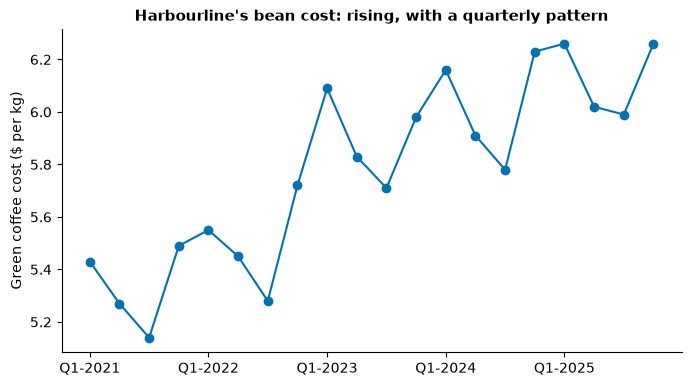

In [7]:
rng = np.random.default_rng(33)
n_q = 20
season_shape = np.tile([0.16, -0.04, -0.20, 0.08], n_q // 4)
level = 5.20 + np.cumsum(0.05 + rng.normal(0, 0.09, n_q))
bean = pd.DataFrame({
    "period": np.arange(1, n_q + 1),
    "cost_per_kg": np.round(level + season_shape + rng.normal(0, 0.04, n_q), 2),
    "quarter": [f"Q{q}-{y}" for y in range(2021, 2026) for q in range(1, 5)],
})
print(bean.to_string(index=False))

wide = bean.assign(year=bean["quarter"].str[-4:], q=bean["quarter"].str[:2]).pivot(index="year", columns="q", values="cost_per_kg")
print("\nAverage cost by year:\n", wide.mean(axis=1).round(2).to_string())
print("\nAverage difference from the year's mean, by quarter:\n", wide.sub(wide.mean(axis=1), axis=0).mean().round(2).to_string())

fig, ax = plt.subplots()
ax.plot(bean["period"], bean["cost_per_kg"], marker="o", color=BLUE)
ax.set_xticks(bean["period"][::4], bean["quarter"][::4])
ax.set_ylabel("Green coffee cost ($ per kg)")
ax.set_title("Harbourline's bean cost: rising, with a quarterly pattern")
plt.show()

The descriptive step already says a lot. The cost has **risen** by about 80 cents a kilogram (about 15%) over five years, and it has a **seasonal pattern**: the fourth and first quarters are usually the dearest and the third the cheapest, a swing of about 35 cents within a year. A forecast for 2026 must capture both. The columns `period` and `quarter` are deliberate: Excel's forecasting tools need a **numeric** timeline (`period`), while people read the `quarter` labels (Part 6).

To use these numbers in Excel, copy the printed table into a sheet named `History` with `period` in `A1:A21`, `cost_per_kg` in `B1:B21` and `quarter` in `C1:C21`, or run `print(bean.to_csv(index=False))` and paste the result into Excel with **Data → Text to Columns** (comma).

> **Predict.** At today's prices, option A is clearly cheapest. Before forecasting, which option do you expect the board to choose, and what would change your mind?

---

## Part 6: Forecasting with Excel Forecast Sheet: ETS, seasonality and intervals (core)

Day 3 introduced exponential smoothing in Python. Excel offers the same family of models in two places: the **Forecast Sheet** button, which builds a forecast table and chart in one step, and the **`FORECAST.ETS`** functions, which do the same cell by cell.

### What ETS does, in one paragraph

**ETS** stands for **E**rror, **T**rend and **S**easonality. The model keeps three running estimates, each updated every period as a weighted average of "what the newest data says" and "what we believed before":

- the **level** (where the series is now), updated with weight **α** (alpha);
- the **trend** (how much it rises per period), with weight **β** (beta);
- the **seasonal effect** of each quarter (how far that quarter usually sits above or below the level), with weight **γ** (gamma).

A weight near 1 means "follow the latest data"; near 0 means "change slowly". The forecast for *h* periods ahead is: level + *h* × trend + that quarter's seasonal effect. Excel uses the **additive** version of all three parts (Microsoft calls it the **AAA** version of ETS): errors, trend and seasonal effects are **added** in dollars, not multiplied in percentages.

### Seasonality detection

Excel can **detect** the season length itself. Roughly, it looks for the lag at which the series (after removing the trend) is most strongly correlated with itself: in quarterly data with a yearly pattern, the value four quarters ago. The Python cell below does a similar check by hand, so you can see what "detection" means.

> **Predict, then run.** In the detrended bean cost, which lag between 1 and 8 quarters will have the highest autocorrelation?

In [8]:
y = bean["cost_per_kg"].to_numpy()
detrended = np.diff(y)                     # first differences remove the trend
acf = {lag: np.corrcoef(detrended[lag:], detrended[:-lag])[0, 1] for lag in range(1, 9)}
for lag, r in acf.items():
    print(f"lag {lag}: {r:+.2f}  {'#' * int(max(r, 0) * 30)}")
strong = [lag for lag, r in acf.items() if r > 0.5]
print("\nLags with autocorrelation above 0.5:", strong, "-> season length", min(strong), "quarters")

lag 1: -0.05  
lag 2: -0.86  
lag 3: +0.03  #
lag 4: +0.84  #########################
lag 5: -0.08  
lag 6: -0.89  
lag 7: +0.16  ####
lag 8: +0.87  ##########################

Lags with autocorrelation above 0.5: [4, 8] -> season length 4 quarters


Lags **4 and 8** stand out: this quarter looks like the same quarter one and two years ago. That is what a season length of 4 means. In Excel, the function `=FORECAST.ETS.SEASONALITY(B2:B21, A2:A21)` returns the season length Excel detects (0 means it found none). Check it before trusting an automatic forecast: a series that is too short, or noisy, may give 0 or an odd length.

### The Excel click path: Forecast Sheet

On the `History` sheet (period in column A, cost in B, quarter labels in C):

1. **Select the timeline and the values**, side by side with their headers: `A1:B21`. Keep the text labels out of the selection.
2. **Data → Forecast Sheet** (in the *Forecast* group, next to What-If Analysis). A preview window opens with the history and a forecast.
3. Choose the **line** chart (left icon) or the column chart.
4. **Forecast End:** type **28** (period 28 = Q4-2027, eight quarters after period 20).
5. Click **Options** and check each setting:
   - **Forecast Start**: the last actual period (20) by default. Leave it.
   - **Confidence Interval**: **95%** by default. You can type another level (Part 7 uses this).
   - **Seasonality**: *Detect Automatically*, or *Set Manually* and type **4**.
   - **Include forecast statistics**: tick it to get α, β, γ and error measures (MAE, RMSE, MASE, SMAPE).
   - **Timeline Range** and **Values Range**: should show `$A$2:$A$21` and `$B$2:$B$21`.
   - **Fill Missing Points Using**: *Interpolation*. **Aggregate Duplicates Using**: *Average*.
6. Click **Create**. Excel adds a **new sheet** with a table and a chart.

The new table has five columns: **Timeline**, **Values** (the history), **Forecast**, **Lower Confidence Bound** and **Upper Confidence Bound**. For the history rows the last three are empty, except the **last actual row**, where Excel copies the actual value into all three so that the chart's lines join. The forecast rows (periods 21 to 28) hold formulas such as

`=FORECAST.ETS(A22, $B$2:$B$21, $A$2:$A$21, 1, 1)` for the forecast, and
`=C22 + FORECAST.ETS.CONFINT(A22, $B$2:$B$21, $A$2:$A$21, 0.95, 1, 1)` for the upper bound

(the exact columns depend on where Excel places the table). So you can always find the bound for a given future period by reading **across that period's row** to the *Upper Confidence Bound* column, and you can check any cell by clicking it and reading its formula.

### The timeline must be numeric

Forecast Sheet needs a timeline of **numbers or dates with a constant step**. Text labels such as `Q1-2025` are not a timeline: Excel cannot tell how far apart they are, and Forecast Sheet refuses them or does not offer the expected options. Two fixes:

- **Period numbers** 1, 2, 3, … (always safe). The forecast end is then a period number: to forecast four quarters past period *n*, set Forecast End to *n* + 4.
- **Real dates**, one per quarter, three calendar months apart (for example the first or the last day of each quarter). Excel recognises steps measured in months. If Excel still complains, fall back to period numbers.

Keep the readable labels in another column for your report.

### The functions, for a forecast without the button

| Function | Returns |
|---|---|
| `FORECAST.ETS(target, values, timeline, [seasonality], [data_completion], [aggregation])` | The point forecast for the target period. Seasonality: 1 (or omitted) = detect, 0 = none, a number = that length |
| `FORECAST.ETS.CONFINT(target, values, timeline, [confidence_level], …)` | The **half-width** of the interval: forecast ± this number. Default level 0.95 |
| `FORECAST.ETS.SEASONALITY(values, timeline, …)` | The detected season length |
| `FORECAST.ETS.STAT(values, timeline, statistic_type, …)` | One fitted statistic: 1 = α, 2 = β, 3 = γ, 4 = MASE, 5 = SMAPE, 6 = MAE, 7 = RMSE, 8 = step size |
| `FORECAST.LINEAR(target, values, timeline)` | A straight-line trend forecast, for comparison (Day 5) |

### The Python mirror

`statsmodels` has the same model: `ETSModel` with additive error, trend and seasonality. Excel's fitting procedure is not published in full and differs in details (starting values, how the parameters are optimised), so expect numbers that are **close to Excel's but not identical**, usually within a few cents here. When you report, quote the tool you used.

> **Predict, then run.** Will the 95% interval for Q4-2027 be wider or narrower than for Q1-2026? By roughly how much?

In [9]:
y_q = pd.Series(bean["cost_per_kg"].to_numpy(), index=pd.date_range("2021-01-01", periods=n_q, freq="QS"))
fits = {}
for name, seasonal in [("trend only (AAN)", None), ("trend + season (AAA)", "add")]:
    fits[name] = ETSModel(y_q, error="add", trend="add", seasonal=seasonal,
                          seasonal_periods=4 if seasonal else None).fit(disp=False)
    print(f"{name:<22} AIC {fits[name].aic:7.1f}   in-sample RMSE {np.sqrt(fits[name].mse):.3f}")

ets = fits["trend + season (AAA)"]
print("\nSmoothing weights:", {k: round(v, 3) for k, v in zip(ets.param_names, ets.params) if k.startswith("smoothing")})

fc = ets.get_prediction(start="2026-01-01", end="2027-10-01").summary_frame(alpha=0.05)
table = pd.DataFrame({"period": np.arange(21, 29),
                      "quarter": [f"Q{q}-{y}" for y in (2026, 2027) for q in range(1, 5)],
                      "forecast": fc["mean"].to_numpy(),
                      "lower_95": fc["pi_lower"].to_numpy(), "upper_95": fc["pi_upper"].to_numpy()})
table["width"] = table["upper_95"] - table["lower_95"]
print("\n", table.round(2).to_string(index=False))

trend only (AAN)       AIC    -2.3   in-sample RMSE 0.178
trend + season (AAA)   AIC   -25.6   in-sample RMSE 0.077

Smoothing weights: {'smoothing_level': 0.655, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0}

  period quarter  forecast  lower_95  upper_95  width
     21 Q1-2026      6.45      6.29      6.60   0.30
     22 Q2-2026      6.24      6.06      6.42   0.36
     23 Q3-2026      6.13      5.92      6.33   0.41
     24 Q4-2026      6.48      6.25      6.71   0.46
     25 Q1-2027      6.65      6.40      6.90   0.50
     26 Q2-2027      6.44      6.17      6.71   0.54
     27 Q3-2027      6.33      6.04      6.62   0.57
     28 Q4-2027      6.68      6.38      6.99   0.61


How to read this output:

- The **seasonal model** has a much lower AIC (the lower the better; Day 3) and a smaller in-sample error than the trend-only model, so the quarterly pattern is real enough to keep. Excel's automatic detection should agree.
- The **forecast** keeps both the trend and the quarterly shape: Q4 and Q1 high, Q3 low.
- The **interval widens** with the horizon, from about 30 cents wide one quarter ahead to about 60 cents two years ahead. Each step ahead adds new uncertainty to the uncertainty already there. An interval that did **not** widen would be claiming knowledge the model does not have.

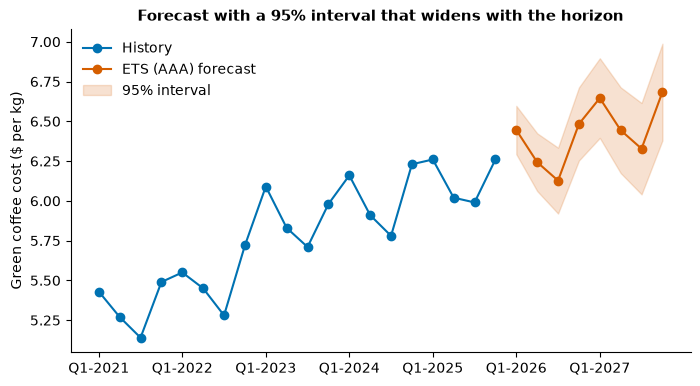

In [10]:
fig, ax = plt.subplots()
ax.plot(bean["period"], bean["cost_per_kg"], marker="o", color=BLUE, label="History")
ax.plot(table["period"], table["forecast"], marker="o", color=ORANGE, label="ETS (AAA) forecast")
ax.fill_between(table["period"], table["lower_95"], table["upper_95"], color=ORANGE, alpha=0.18,
                label="95% interval")
ax.set_xticks(list(bean["period"][::4]) + [21, 25], list(bean["quarter"][::4]) + ["Q1-2026", "Q1-2027"])
ax.set_ylabel("Green coffee cost ($ per kg)")
ax.set_title("Forecast with a 95% interval that widens with the horizon")
ax.legend(frameon=False, loc="upper left")
plt.show()

> **Misconception:** "A 95% confidence interval means the forecast is 95% accurate." It means that, **if the model is right**, the actual value should fall inside the band about 95 times in 100. Two cautions. First, the band assumes the future behaves like the past; a shock the history never showed (a frost in Brazil, a shipping crisis) can push the actual value outside it. Second, Excel calls it a *confidence* interval, but statisticians would call it a **prediction interval**: it covers a future **value**, not just the average, which is why it is wide.

> **Misconception:** "More history always helps." More **relevant** history helps. If the market changed structurally three years ago, older data pulls the forecast towards a world that no longer exists. And for seasonality, ETS needs at least two full seasons to estimate the pattern; with fewer, set seasonality to 0.

### Common Forecast Sheet problems

| Symptom | Likely cause | Fix |
|---|---|---|
| The Forecast Sheet button is greyed out | No cell inside the data is selected, the sheet is protected, or the Excel version is too old | Click inside the data; use desktop Excel 2016 or later |
| Excel complains about the timeline | Text labels, uneven steps, or a blank in the timeline | Use period numbers 1, 2, 3, …, or evenly spaced dates |
| The forecast has no seasonal shape | Detection found no season (short or noisy series) | Check `FORECAST.ETS.SEASONALITY`; set it manually only if you have a business reason and two or more full seasons |
| The forecast goes too few periods ahead | Forecast End was left at the default | Set Forecast End to the last period you need |
| Your numbers differ slightly from a classmate's Python output | Excel and statsmodels fit the same model differently | Expected. Quote Excel's numbers if your work is in Excel |
| Your numbers differ from a classmate's Excel | Different data, a different confidence level or a manual seasonality setting | Compare the Options settings and the data cell by cell |

---

## Part 7: Planning against an upper bound (core)

A forecast gives a **point** (the middle) and an **interval**. Which number should feed the plan?

The point forecast is right when being wrong **in either direction costs about the same**. Many decisions are **asymmetric**. Harbourline must fix its **2026 bean budget** with its bank now. If actual costs come in **below** budget, the unused money sits idle: a small cost. If they come in **above**, Harbourline must borrow at short notice at a penalty rate, delay payments to farmers, or cut production: a large cost. Say each dollar of **overrun** costs **3 times** as much as each dollar of unused budget.

Decision theory gives a clean answer. If an overrun costs *u* per dollar and an unused dollar costs *o*, the budget that minimises the expected cost is the **quantile** of the forecast distribution at

> *u* ÷ (*u* + *o*)

which is the same **critical ratio** as the newsvendor rule at the end of Day 5, Part 12. With *u* = 3 and *o* = 1 that is the **75th percentile**: plan for a cost that will be exceeded only one year in four.

To find that percentile for the **whole year**, we simulate many possible 2026s from the fitted ETS model and average the four quarters in each.

> **Predict, then run.** Is the 75th percentile of the 2026 average cost closer to the point forecast or to the 95% upper bound?

Point forecast, 2026 average:              $6.325 per kg
 50.0% percentile of the simulated average: $6.325 per kg
 75.0% percentile of the simulated average: $6.380 per kg
 90.0% percentile of the simulated average: $6.427 per kg
 97.5% percentile of the simulated average: $6.487 per kg
Average of the four quarterly upper bounds: $6.517 per kg

Budget with the lowest expected cost: $6.380 per kg (critical ratio 75%; simulated 75th percentile $6.380)


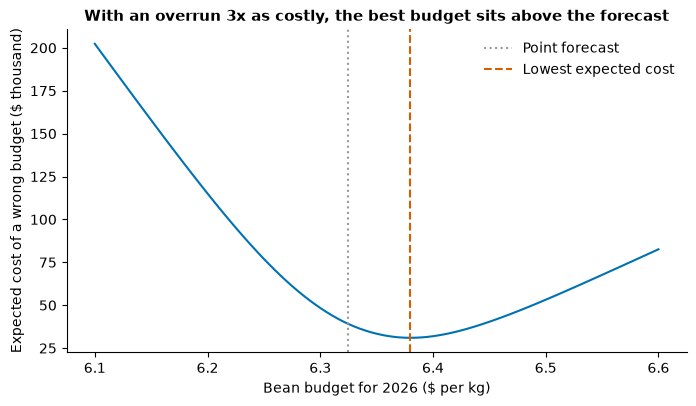

In [11]:
reps = 10_000
errors = np.random.default_rng(2026).normal(0, np.sqrt(ets.mse), size=(4, reps))
paths = ets.simulate(nsimulations=4, anchor="end", repetitions=reps, random_errors=errors)
annual = paths.mean(axis=0).to_numpy()          # average cost per kg over the four quarters of 2026

point = table["forecast"].iloc[:4].mean()
print(f"Point forecast, 2026 average:              ${point:.3f} per kg")
for q in (0.50, 0.75, 0.90, 0.975):
    print(f"{q:>6.1%} percentile of the simulated average: ${np.quantile(annual, q):.3f} per kg")
print(f"Average of the four quarterly upper bounds: ${table['upper_95'].iloc[:4].mean():.3f} per kg")

# Expected cost of each budget level, with an overrun costing 3x an unused dollar
volume = 300_000
budgets = np.linspace(6.10, 6.60, 101)
u, o = 3.0, 1.0
exp_cost = [volume * np.mean(u * np.maximum(annual - b, 0) + o * np.maximum(b - annual, 0)) for b in budgets]
best = budgets[int(np.argmin(exp_cost))]
print(f"\nBudget with the lowest expected cost: ${best:.3f} per kg "
      f"(critical ratio {u / (u + o):.0%}; simulated 75th percentile ${np.quantile(annual, 0.75):.3f})")

fig, ax = plt.subplots()
ax.plot(budgets, np.array(exp_cost) / 1000, color=BLUE)
ax.axvline(point, color=GREY, ls=":", label="Point forecast")
ax.axvline(best, color=ORANGE, ls="--", label="Lowest expected cost")
ax.set_xlabel("Bean budget for 2026 ($ per kg)")
ax.set_ylabel("Expected cost of a wrong budget ($ thousand)")
ax.set_title("With an overrun 3x as costly, the best budget sits above the forecast")
ax.legend(frameon=False)
plt.show()

Four things to take from this.

1. **The best budget is above the point forecast**, at about the 75th percentile, because an overrun hurts three times as much. Budgeting at the point forecast is not "neutral": it accepts a 50% chance of the expensive mistake.
2. **The 95% upper bound is one particular quantile**: the 97.5th percentile. It is the right planning number when an overrun is roughly **39 times** as costly as unused budget (0.975 = 39 ÷ 40), for example when an overrun would break a loan covenant or a fixed-price contract. For milder asymmetries, a lower bound is better. Choose the quantile from the **consequences**, not by habit.
3. **Quarterly bounds do not add up to an annual bound.** The average of the four quarterly upper bounds is higher than the 97.5th percentile of the annual average, because four quarters are unlikely to all land at their worst together. For a single quarter (one future period), the bound Excel prints is the right number; for a total over several periods, simulate.
4. **Excel can give any quantile for a single period.** The upper bound of a two-sided interval at confidence level *c* is the **(1 + *c*) ÷ 2** quantile. For the 75th percentile, use *c* = 0.50: `=FORECAST.ETS(22,History!B$2:B$21,History!A$2:A$21,4) + FORECAST.ETS.CONFINT(22,History!B$2:B$21,History!A$2:A$21,0.5,4)` gives the 75th percentile for period 22.

> **Misconception:** "Planning on the upper bound is pessimism." It is matching the plan to the **shape of the risk**. The upper bound is not a prediction that costs will be high; it is the cost the plan must survive.

### Which option at which bound?

Now return to Harbourline's three sourcing options (Part 5). Options A and B pay the market price, so their cost moves with the forecast; option C pays a fixed $7.00. Compare profit at the point forecast and at the 97.5th percentile of the simulated 2026 average.

> **Predict, then run.** At the point forecast, B is cheaper than C. Is it still cheaper at the upper bound?

In [12]:
revenue_per_kg, other_var, fixed = 22.00, 9.50, 1_400_000


def profit(bean_cost_per_kg):
    return volume * (revenue_per_kg - other_var - bean_cost_per_kg) - fixed


def option_cost(option, market):
    return {"A. Spot, conventional": market, "B. Spot, certified": market + 0.60,
            "C. Direct-trade contract": np.full_like(market, 7.00)}[option]


upper = np.quantile(annual, 0.975)
rows = []
for opt in ["A. Spot, conventional", "B. Spot, certified", "C. Direct-trade contract"]:
    sim_profit = profit(option_cost(opt, annual))
    rows.append({"option": opt,
                 "profit at point forecast": usd(profit(option_cost(opt, np.array(point)))),
                 "profit at 97.5th percentile": usd(profit(option_cost(opt, np.array(upper)))),
                 "spread of profit (P2.5 to P97.5)": usd(np.quantile(sim_profit, 0.975) - np.quantile(sim_profit, 0.025))})
print(pd.DataFrame(rows).to_string(index=False))

                  option profit at point forecast profit at 97.5th percentile spread of profit (P2.5 to P97.5)
   A. Spot, conventional                 $452,597                    $403,821                          $97,463
      B. Spot, certified                 $272,597                    $223,821                          $97,463
C. Direct-trade contract                 $250,000                    $250,000                               $0


At the point forecast, the certified spot option B beats the contract C by about $20,000. At the upper bound the order **reverses**: the contract's fixed price protects it, while B carries the full market risk **plus** the premium. Option C also has **no spread** at all in bean cost: its profit is known in advance, which has value for a company with a bank budget to meet.

That reversal is the reason to look at the bound. When options carry **different exposure** to the uncertain driver, the ranking can change between the middle and the tail of the forecast. When every option shifts by the same amount (a fixed premium on the same market price), the ranking cannot change, but the bound still tells you whether the chosen option stays profitable.

Option A is the cheapest at both points. Whether that settles the decision is the subject of Parts 8 to 14: the board also cares about the people and the land that grow the coffee, and about what its customers and lenders expect.

> **Check your understanding.** A café chain signs a two-year fixed-price lease and wants to budget its electricity. Overspending its budget forces it to close for a month; underspending costs nothing. Which percentile would you plan on, and would Excel's default 95% interval be enough?

---

## Part 8: Privacy, PIPL, GDPR and consent (core)

The rest of the lecture asks a different question: not "is the analysis right?" but "is it **right to do**, and right to do **this way**?" Ethics in analytics is not a separate subject added at the end; each choice in the value chain (what to collect, how to define a KPI, which model to deploy, what to recommend) has consequences for people.

### Why personal data needs special care

Harbourline's loyalty app records who bought what, where and when. That data improves offers and stock planning. It can also reveal a person's routine, health (decaf every day after a diagnosis?), religion (fasting months) or income. **Personal information** is any information about an identified or **identifiable** person, and "identifiable" is broader than most people think.

### Two laws you will meet

| | China: **Personal Information Protection Law (PIPL)** | EU: **General Data Protection Regulation (GDPR)** |
|---|---|---|
| In force | 1 November 2021 | 25 May 2018 |
| Applies to | Processing in China, and processing abroad that targets or analyses people in China | Processing in the EU, and processing abroad that targets or monitors people in the EU |
| Legal bases | Consent, or one of several others (a contract with the person, HR management, legal duties, public-health emergencies, news reporting, reasonable use of information the person made public) | Six lawful bases: consent, contract, legal obligation, vital interests, public task, legitimate interests |
| Consent | Informed, voluntary and explicit; can be withdrawn; **separate consent** needed for sensitive information, for sharing with another handler, for making it public and for transfer abroad | Freely given, specific, informed and unambiguous; as easy to withdraw as to give |
| Sensitive data | Includes biometrics, religious belief, specific identities, health, financial accounts, location tracking, and all data on children under 14 | "Special categories": health, biometrics, religion, ethnicity, sexual orientation, political opinions, trade-union membership, genetics |
| Automated decisions | Must be transparent and fair, with **no unreasonable differences in prices or terms** between people; people can ask for an explanation and refuse decisions made solely by automated means that significantly affect them | Right not to be subject to a solely automated decision with legal or similarly significant effects, with safeguards |
| Impact assessment | Required before processing sensitive data, automated decision-making, sharing or transfer abroad | Data protection impact assessment (DPIA) for high-risk processing |
| Moving data abroad | A security assessment, a standard contract or certification, depending on volume and type | Adequacy decision, standard contractual clauses or other safeguards |
| Penalties | Up to 50 million yuan or 5% of the previous year's turnover for serious cases | Up to €20 million or 4% of worldwide annual turnover |

China's **Data Security Law** (2021) and **Cybersecurity Law** (2017) sit alongside PIPL, and the 2022 penalty of more than 8 billion yuan imposed on the ride-hailing company Didi for data violations showed that enforcement is real. This table is a summary for analysts, not legal advice; a company's legal or compliance team applies the details.

The principles behind both laws are the same and are what an analyst can apply every day:

1. **Purpose limitation:** collect for a stated purpose and do not quietly reuse the data for another.
2. **Data minimisation:** collect and keep only what the purpose needs. An analysis of café traffic does not need names.
3. **Storage limitation:** delete or anonymise when the purpose is served.
4. **Security and access control:** only those who need personal data can see it (Part 2's governance roles).
5. **Transparency and rights:** people can find out what is held about them, correct it and, in many cases, delete it.

### Consent that means something

Consent is valid only if the person **understood** what they agreed to and **could have said no**. Warning signs of consent that does not mean much:

- **Bundling:** "agree to marketing or you cannot use the app."
- **Pre-ticked boxes** and **dark patterns**: a bright "Accept all" next to a grey "Manage settings" three screens deep.
- **Vague purposes:** "to improve our services" covering profiling, resale and model training.
- **No real withdrawal:** opting out takes a phone call.

PIPL's **separate consent** requirement means, for example, that Harbourline could not hide "we share your purchase history with partner brands" inside the general terms: it needs its own clear request.

### "Anonymous" data often is not

Removing names is **pseudonymisation**, not anonymisation. Combinations of ordinary fields (**quasi-identifiers**) can single people out. In a well-known study, Latanya Sweeney estimated that about 87% of the US population could be uniquely identified by ZIP code, birth date and sex alone; and researchers re-identified people in Netflix's "anonymised" movie-ratings data by matching it to public reviews.

A simple measure is **k-anonymity**: every combination of quasi-identifiers must be shared by at least *k* people. Below, 3,000 synthetic Harbourline loyalty members with no names at all.

> **Predict, then run.** The app stores each member's district (8 districts), birth month and year (for birthday offers, years 1960 to 2005) and gender. What share of members is **unique** on those fields: about 5%, 25% or 75%?

In [13]:
rng = np.random.default_rng(88)
m = 3000
members = pd.DataFrame({
    "district": rng.choice([f"D{i}" for i in range(1, 9)], m),
    "birth_year": rng.integers(1960, 2006, m),
    "birth_month": rng.integers(1, 13, m),                     # collected for birthday offers
    "gender": rng.choice(["F", "M"], m),
    "visits_per_week": rng.poisson(2.2, m),
})


def k_report(df, cols):
    size = df.groupby(cols)[cols[0]].transform("size")         # how many members share each combination
    return {"combinations": df.groupby(cols).ngroups, "unique (k = 1)": f"{(size == 1).mean():.1%}",
            "in groups smaller than 5": f"{(size < 5).mean():.1%}", "smallest group (k)": int(size.min())}


general = members.assign(age_band=((2025 - members["birth_year"]) // 10 * 10).astype(str) + "s",
                         zone=np.where(members["district"].isin(["D1", "D2", "D3", "D4"]), "North", "South"))
print(pd.DataFrame({"raw: district, birth month and year, gender": k_report(members, ["district", "birth_year", "birth_month", "gender"]),
                    "generalised: zone, age band, gender": k_report(general, ["zone", "age_band", "gender"])}))

                         raw: district, birth month and year, gender generalised: zone, age band, gender
combinations                                                    2530                                  20
unique (k = 1)                                                 70.7%                                0.0%
in groups smaller than 5                                       99.7%                                0.0%
smallest group (k)                                                 1                                  93


With no names at all, most members are **unique** on these ordinary fields, and almost all sit in groups smaller than five. Anyone who knows a neighbour's district, birthday and gender could find their visit pattern. **Generalising** (zones instead of districts, ten-year age bands instead of birth years) raises the smallest group to about ninety people, at the cost of detail. That trade-off between privacy and analytical precision is a decision to make deliberately, and it belongs in the data-governance rules.

**Excel.** In a helper column, `=COUNTIFS(A:A, A2, B:B, B2, C:C, C2)` gives each row's group size *k*; `=COUNTIF(E:E, 1)/COUNT(E:E)` is the share of unique rows. Generalise with `=FLOOR(2025-B2, 10)` for age bands.

Stronger techniques exist (adding calibrated noise, known as **differential privacy**, or generating synthetic data), but the analyst's first defences are the principles above: do not collect what you do not need, and do not publish row-level data that someone could match.

> **Misconception:** "It's legal, so it's ethical." Laws set a floor and lag behind technology. Target, the US retailer, was reported in 2012 to have used purchase patterns to predict which customers were pregnant and send them baby-product offers; it was probably lawful, and many customers still found it intrusive. A useful test is the **front-page test**: would the people in the data be comfortable reading exactly what you did with it?

---

## Part 9: Bias and fairness: a disparate-impact demonstration (core)

A model can treat groups of people differently even when nobody intends it. Common sources of bias:

| Source | What happens | Example |
|---|---|---|
| **Historical bias** | The data records past decisions that were themselves unfair | A model trained on past loan approvals copies past officers' prejudices |
| **Representation bias** | Some groups are under-represented in the data | A face-recognition model trained mostly on one skin tone |
| **Measurement bias** | The label measures the wrong thing, or measures it worse for some groups | Using "arrests" as a stand-in for "crime" |
| **Proxy variables** | A feature stands in for a protected one | Postcode or district standing in for ethnicity or migrant status |
| **Deployment bias** | A model is used for a purpose or population it was not built for | A credit model from one country used in another |

### The demonstration

Harbourline plans to offer **instant credit** in its app for buying coffee machines. A credit partner has 5,000 past applicants with their **monthly income**, a **credit score**, their **district**, whether a loan officer **approved** them in the past, and whether they **repaid**. Applicants belong to two groups, **A** and **B**, standing for any protected characteristic (for example gender, ethnicity or migrant status). Group membership is **not** used by the model. In this synthetic data, as often in reality, group B lives mainly in two districts, earns a little less on average, and past officers approved group B less often than its repayment record justified.

The **disparate-impact ratio** compares approval rates:

> DI = (approval rate of group B) ÷ (approval rate of group A)

A common screening rule, the **four-fifths rule** from US employment guidelines, treats a ratio below **0.8** as a warning sign that needs investigating. It is a rule of thumb, not a proof of discrimination, and other jurisdictions use other tests.

> **Predict, then run.** A model trained to copy past officers' approvals, **without** the group column but **with** district: will its DI ratio be above or below 0.8?

In [14]:
rng = np.random.default_rng(300)
n_app = 5000
in_b = (rng.random(n_app) < 0.4).astype(int)
apps = pd.DataFrame({"group": np.where(in_b == 1, "B", "A")})
apps["district"] = np.where(rng.random(n_app) < np.where(in_b == 1, 0.7, 0.15),
                            rng.choice(["East", "South"], n_app), rng.choice(["North", "West", "Centre", "Harbour"], n_app))
inc = rng.normal(0, 1, n_app) - 0.25 * in_b                      # group B earns a little less on average
hist = rng.normal(0, 1, n_app)
apps["monthly_income"] = np.round(4200 * np.exp(0.35 * inc), -1)
apps["credit_score"] = np.round(650 + 70 * hist).clip(400, 850)
apps["repaid"] = (rng.random(n_app) < 1 / (1 + np.exp(-(1.8 + 0.9 * inc + 1.0 * hist)))).astype(int)
# Past officers: same evidence, plus an unjustified penalty on group B
apps["past_approved"] = ((0.9 * inc + 1.0 * hist - 1.0 * in_b + rng.normal(0, 0.7, n_app)) > -0.4).astype(int)
print(apps.groupby("group")[["repaid", "past_approved"]].mean().round(3).rename(
    columns={"repaid": "repayment rate", "past_approved": "past approval rate"}))


def features(df, with_district):
    X = pd.DataFrame({"log_income": np.log(df["monthly_income"]), "credit_score": df["credit_score"]})
    if with_district:
        X = X.join(pd.get_dummies(df["district"], prefix="district", drop_first=True).astype(float))
    return X


def audit(label, with_district, approve_share=0.6):
    X = features(apps, with_district)
    model = LogisticRegression(max_iter=5000).fit(X, apps[label])
    score = model.predict_proba(X)[:, 1]
    approved = score >= np.quantile(score, 1 - approve_share)       # approve the top 60% of scores
    rate = pd.Series(approved).groupby(apps["group"]).mean()
    good = apps["repaid"] == 1
    tpr = pd.Series(approved[good]).groupby(apps.loc[good, "group"].to_numpy()).mean()
    return model, {"approval A": rate["A"], "approval B": rate["B"], "DI ratio": rate["B"] / rate["A"],
                   "repayers approved A": tpr["A"], "repayers approved B": tpr["B"],
                   "default rate among approved": 1 - apps.loc[approved, "repaid"].mean()}


results = {}
for name, label, with_d in [("1. copy past approvals, with district", "past_approved", True),
                            ("2. copy past approvals, no district", "past_approved", False),
                            ("3. predict repayment, no district", "repaid", False)]:
    model_i, results[name] = audit(label, with_d)
fair_model = model_i                                                 # model 3, used again in Part 10
print("\n", pd.DataFrame(results).T.round(3).to_string())

       repayment rate  past approval rate
group                                    
A               0.802               0.611
B               0.761               0.276

                                        approval A  approval B  DI ratio  repayers approved A  repayers approved B  default rate among approved
1. copy past approvals, with district       0.663       0.502     0.758                0.756                0.592                        0.091
2. copy past approvals, no district         0.632       0.550     0.870                0.724                0.648                        0.089
3. predict repayment, no district           0.630       0.553     0.877                0.721                0.651                        0.091


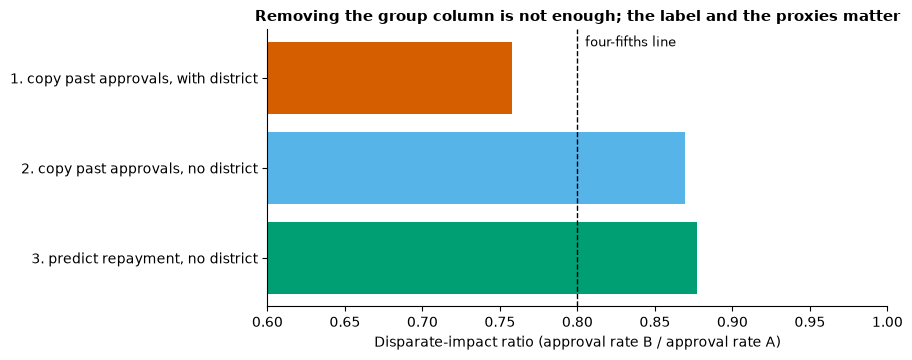

In [15]:
res = pd.DataFrame(results).T
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(res.index[::-1], res["DI ratio"][::-1], color=[GREEN, SKY, ORANGE])
ax.axvline(0.8, color="black", ls="--", lw=1)
ax.text(0.805, 2.35, "four-fifths line", fontsize=9)
ax.set_xlim(0.6, 1.0)
ax.set_xlabel("Disparate-impact ratio (approval rate B / approval rate A)")
ax.set_title("Removing the group column is not enough; the label and the proxies matter")
plt.show()

What the audit shows:

1. **Model 1 falls below the four-fifths line** although it never sees the group column. It learnt the past officers' penalty on group B **through district**, which stands in for group membership. "We don't use the protected attribute" (**fairness through unawareness**) is not a defence.
2. **Dropping the proxy (model 2)** raises the ratio, but the model still copies a biased label.
3. **Changing the label (model 3)**, so the model predicts **repayment** instead of copying **past approvals**, gives the fairest result here, with **the same default rate** among approved applicants. Being fairer did not cost accuracy in this case; it often costs less than people assume, because the biased decisions were also **worse** decisions.
4. **A gap remains**, because group B's incomes are lower on average and income genuinely predicts repayment. Whether that gap is acceptable is a **value judgement**, not a statistical one: it depends on the law, the purpose (credit, hiring, insurance) and the organisation's values.

### Which fairness measure?

| Measure | Equal across groups | Question it answers |
|---|---|---|
| **Demographic parity** (DI ratio) | Approval rates | Do groups get the benefit at similar rates? |
| **Equal opportunity** | Approval rates among people who **would** repay (true-positive rates) | Are qualified people treated alike? |
| **Predictive parity** | Repayment rates among the **approved** | Does a "yes" mean the same in each group? |
| **Calibration** | For each score, the actual repayment rate | Does a score of 0.7 mean 70% in every group? |

When groups differ in their underlying rates, these measures **cannot all be equal at once** (results by Kleinberg, Mullainathan and Raghavan, and by Chouldechova, prompted by the debate over the COMPAS risk scores used in US courts). So an organisation must **choose** which fairness it is committing to, write that choice down and justify it. That choice belongs to the business owner and the ethics or compliance function, informed by the analyst, not to the analyst alone.

**Excel.** With the approvals in column F and groups in column A: `=AVERAGEIFS(F:F, A:A, "B")/AVERAGEIFS(F:F, A:A, "A")` is the DI ratio; add a condition `G:G, 1` (repaid) for the equal-opportunity rates.

> **Misconception:** "The algorithm is objective because it is maths." A model is a summary of its training data and of the choices made in building it: which label, which features, which threshold. Each choice can introduce or remove bias.

---

## Part 10: Transparency and explainability (core)

People affected by a decision, and the managers responsible for it, need to know **why** it was made. Both PIPL and GDPR give people rights in relation to automated decisions (Part 8), and lenders in many countries must give **reasons** when they decline credit.

Two kinds of explanation:

- **Global:** how the model works overall. Which features matter, in which direction? For a linear or logistic model, the coefficients answer this (Day 4). For complex models, tools such as permutation importance or SHAP values estimate it.
- **Local:** why **this** person got **this** decision. For a logistic model, each feature's contribution to the score is its coefficient times how far the person's value is from the average.

> **Predict, then run.** An applicant with a below-average credit score and an average income is declined by model 3. Which reason will come first?

In [16]:
X3 = features(apps, with_district=False)
coefs = pd.Series(fair_model.coef_[0], index=X3.columns)
print("Global view (coefficients):", coefs.round(4).to_dict())

score3 = fair_model.predict_proba(X3)[:, 1]
cutoff = np.quantile(score3, 0.4)
declined = np.where(score3 < cutoff)[0]
person = declined[np.argmin(np.abs(X3.iloc[declined]["log_income"] - X3["log_income"].mean()))]
contrib = coefs * (X3.iloc[person] - X3.mean())                      # push on the log-odds, relative to average
print(f"\nApplicant {person}: income ${apps.loc[person, 'monthly_income']:,.0f}, credit score {apps.loc[person, 'credit_score']:.0f}, "
      f"score {score3[person]:.2f} (cut-off {cutoff:.2f})")
print("Reasons, largest push towards decline first:")
for feat, c in contrib.sort_values().items():
    print(f"  {feat:<13} {c:+.2f} on the log-odds")

Global view (coefficients): {'log_income': 2.4027, 'credit_score': 0.0147}

Applicant 387: income $4,090, credit score 553, score 0.57 (cut-off 0.80)
Reasons, largest push towards decline first:
  credit_score  -1.41 on the log-odds
  log_income    -0.00 on the log-odds


The explanation names the credit score as the main reason, in a form a person can act on ("your credit score is below what we usually approve; your income is not the issue"). That is a **reason code**, the standard local explanation in credit.

Transparency is more than explaining one decision. Good practice includes:

- **Model cards** (Mitchell and colleagues, 2019): a short document for each model: its purpose, the data it was trained on, its performance overall and **by group**, its limits, and who is responsible.
- **Datasheets for data sets** (Gebru and colleagues): where the data came from, how it was collected, what it should not be used for.
- **Human review** for decisions with significant effects, with the authority to overrule the model.
- **Logging**, so a decision can be reconstructed later.

> **Misconception:** "Explainable means simple." A simple model can still hide a biased label (Part 9, model 1, was a plain logistic regression). And a complex model can be explained well enough for its purpose. The test is whether the people affected and the people accountable can understand and challenge the decision.

---

## Part 11: Goodhart's law and metric gaming (core)

> **Goodhart's law**, as it is usually quoted: when a measure becomes a target, it ceases to be a good measure.

A KPI is useful because it **tracks** something we care about. Once people are rewarded for moving the KPI itself, they find ways to move it that do not move the thing we care about, or that harm it. Related is **Campbell's law**: the more a measure is used for important decisions, the more it is subject to corruption pressures and the more it distorts the process it was meant to monitor.

Famous examples: Wells Fargo's accounts-per-customer target (Part 4); Volkswagen's diesel cars, which detected the emissions test and behaved differently during it (2015); hospitals meeting waiting-time targets by delaying the moment a patient is officially "waiting"; software teams rewarded for lines of code.

**A demonstration.** Harbourline's customer-service centre has 40 agents. Management introduces a bonus for keeping the **average handle time** (AHT) of a call under 6 minutes. Some agents genuinely work faster; others end calls before the problem is solved. Unresolved problems come back as repeat calls.

> **Predict, then run.** After the bonus, AHT falls. Does the total agent time needed to **solve** each customer's problem fall too?

                                  before bonus  after bonus change
average handle time (min)                 7.48         6.25   -16%
first-contact resolution                  0.82         0.67   -19%
calls per problem solved                  1.22         1.68   +38%
agent minutes per problem solved          9.12         9.75    +7%
agent hours per month                  2433.11      2599.31    +7%


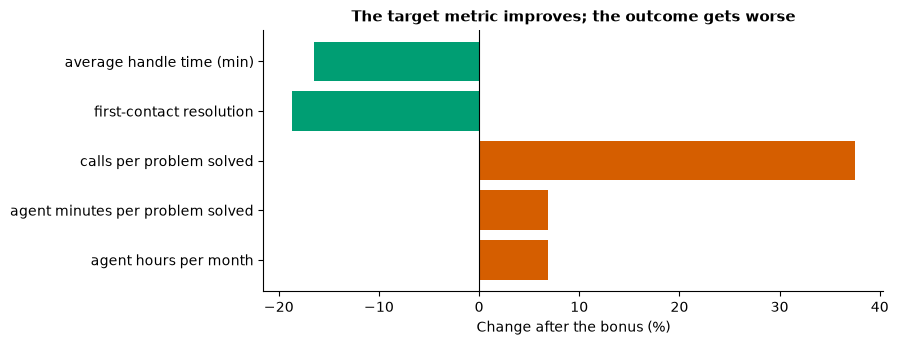

In [17]:
rng = np.random.default_rng(111)
agents, problems_each = 40, 400


def month(gaming_share, speed_up_honest, speed_up_gaming, fcr_honest, fcr_gaming):
    gaming = rng.random(agents) < gaming_share
    base_minutes = rng.normal(7.5, 0.6, agents)
    minutes = base_minutes * np.where(gaming, speed_up_gaming, speed_up_honest)
    fcr = np.where(gaming, fcr_gaming, fcr_honest)                     # first-contact resolution rate
    calls_per_problem = 1 / fcr                                         # repeat calls until solved
    return {"average handle time (min)": np.mean(minutes),
            "first-contact resolution": np.mean(fcr),
            "calls per problem solved": np.mean(calls_per_problem),
            "agent minutes per problem solved": np.mean(minutes * calls_per_problem),
            "agent hours per month": np.sum(minutes * calls_per_problem * problems_each) / 60}


before = month(0.0, 1.0, 1.0, 0.82, 0.82)
after = month(0.40, 0.95, 0.62, 0.81, 0.40)
cmp_ = pd.DataFrame({"before bonus": before, "after bonus": after})
cmp_["change"] = (cmp_["after bonus"] / cmp_["before bonus"] - 1).map("{:+.0%}".format)
print(cmp_.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.4))
pct = (cmp_["after bonus"] / cmp_["before bonus"] - 1) * 100
ax.barh(pct.index[::-1], pct[::-1], color=[ORANGE if v > 0 else GREEN for v in pct[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change after the bonus (%)")
ax.set_title("The target metric improves; the outcome gets worse")
plt.show()

The dashboard KPI (AHT) **improves** by about a sixth, and management might celebrate. But first-contact resolution falls, customers call back more often, and the agent time needed to actually **solve** a problem goes **up**. Customers are worse off and so is the cost base. Nobody broke a rule.

How to design KPIs that resist gaming:

1. **Pair every target with a counter-metric** it could be traded against: handle time with resolution rate; sales with returns and complaints; speed with error rate.
2. **Measure the outcome, not the activity,** where possible: problems solved, not calls closed.
3. **Use a balanced set** (a **balanced scorecard**: financial, customer, process, learning) rather than one number.
4. **Watch for sudden improvements**, and audit a sample: a jump in a KPI with no change in the process is a signal, not just good news.
5. **Ask the people being measured** how the KPI could be gamed, before launch. They know.
6. **Keep some measures for learning only**, not tied to pay.

> **Check your understanding.** Harbourline's purchasing team is rewarded for "average cost per kg below budget". Name two ways that KPI could be gamed in sourcing, and one counter-metric for each.

---

## Part 12: Supply-chain ethics and ESG trade-offs (core)

Most of a product's social and environmental impact sits **upstream**, with suppliers. For Harbourline that means coffee farms: farmer incomes that can fall below a living income when prices drop, child and forced labour risks in some regions, deforestation when farms expand, and climate exposure. In 2013 the collapse of the Rana Plaza factory building in Bangladesh, which made clothes for well-known brands, killed more than 1,100 workers and changed how buyers think about responsibility for suppliers' conditions.

**ESG** (environmental, social and governance) is the umbrella term investors and companies use for these factors. Some useful vocabulary:

- **Scope 1, 2 and 3 emissions:** a company's own direct emissions; emissions from the energy it buys; and everything else in its value chain, including suppliers. For a roaster, Scope 3 (farming and shipping) is usually most of the total.
- **Due diligence:** identifying, preventing and accounting for human-rights and environmental harms in the supply chain. It is increasingly required by law, for example under Germany's Supply Chain Act (in force since 2023) and EU rules on corporate sustainability due diligence and on deforestation-free products (which cover coffee), whose details and timetables have been revised since adoption.
- **Certification and traceability:** independent standards (for example Fairtrade or Rainforest Alliance for coffee) and the ability to trace a bag of beans back to a co-operative or a farm.
- **Greenwashing:** claiming more sustainability than the evidence supports. Regulators increasingly fine it.

### Making the trade-off explicit

Ethical sourcing usually costs money now, while its benefits (lower legal and reputational risk, supply security, customer and employee loyalty, access to customers and lenders who require standards) are real but harder to put in a spreadsheet. Two disciplined ways to bring both into one decision:

1. **Price what you can, describe what you cannot.** The extra cost of option B or C per year, per kg and **per cup** is easy to compute; reputational risk is not, but it can be described with evidence (customer surveys, buyer requirements, past incidents in the industry).
2. **Multi-criteria scoring**, with the weights written down. Below, Harbourline's analysts score the three options from 1 (poor) to 5 (strong) on four non-financial criteria. These scores are **judgements**, made by people and open to challenge; the code only makes the consequences of the weights visible.

                          farmer income  traceability  environment (deforestation, climate)  price-risk protection  profit (scaled 1-5)
A. Spot, conventional                 1             1                                     2                      1                  5.0
B. Spot, certified                    3             3                                     4                      1                  1.4
C. Direct-trade contract              5             5                                     4                      5                  1.0

Option A wins only when profit carries at least 47% of the total weight


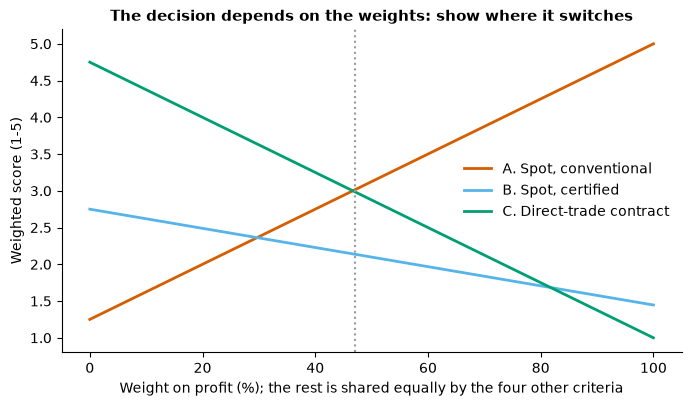

In [18]:
criteria = pd.DataFrame({
    "farmer income": [1, 3, 5],
    "traceability": [1, 3, 5],
    "environment (deforestation, climate)": [2, 4, 4],
    "price-risk protection": [1, 1, 5],
}, index=["A. Spot, conventional", "B. Spot, certified", "C. Direct-trade contract"])
profit_point = pd.Series({opt: profit(option_cost(opt, np.array(point))) for opt in criteria.index})
criteria["profit (scaled 1-5)"] = 1 + 4 * (profit_point - profit_point.min()) / (profit_point.max() - profit_point.min())
print(criteria.round(1).to_string())

non_fin = ["farmer income", "traceability", "environment (deforestation, climate)", "price-risk protection"]
weights_fin = np.linspace(0, 1, 101)
scores = {opt: [w * criteria.loc[opt, "profit (scaled 1-5)"] + (1 - w) * criteria.loc[opt, non_fin].mean()
                for w in weights_fin] for opt in criteria.index}
winner = [max(scores, key=lambda o: scores[o][i]) for i in range(len(weights_fin))]
switch = weights_fin[next(i for i, w in enumerate(winner) if w.startswith("A"))]
print(f"\nOption A wins only when profit carries at least {switch:.0%} of the total weight")

fig, ax = plt.subplots()
for opt, col in zip(criteria.index, [ORANGE, SKY, GREEN]):
    ax.plot(weights_fin * 100, scores[opt], color=col, lw=2, label=opt)
ax.axvline(switch * 100, color=GREY, ls=":")
ax.set_xlabel("Weight on profit (%); the rest is shared equally by the four other criteria")
ax.set_ylabel("Weighted score (1-5)")
ax.set_title("The decision depends on the weights: show where it switches")
ax.legend(frameon=False)
plt.show()

The chart is more useful than any single weighted score: it shows the board **how much weight on profit** it would take for the conventional option to win. If the board's honest answer is "less than that", the decision is made; if not, the disagreement is now about values, stated openly, rather than hidden in a spreadsheet.

Two rules keep multi-criteria scoring honest:

- **Red lines are constraints, not weights.** If an option involves forced or child labour, no profit advantage can compensate for it, so it is **excluded**, not scored low. Putting it in the scoring implies a price at which it would be acceptable.
- **Write down the weights before seeing the scores**, and test how sensitive the answer is to them (exactly as you did with decision rules in Day 5, Part 12).

> **Misconception:** "Ethics and profit are always in conflict." Sometimes they are, in the short run, and pretending otherwise is greenwashing. But over longer horizons many ethical choices also **reduce risk**: option C's fixed price protects Harbourline in a bad year (Part 7), and secure relationships with farmers protect supply when markets are tight. A good recommendation states both the cost and the risk reduction.

---

## Part 13: Responsible-AI frameworks (core summary, extension detail)

Several frameworks turn the ideas of Parts 8 to 12 into checklists and rules. You do not need to memorise them; you should recognise them and be able to use one as a structure for a review.

| Framework | From | Core idea |
|---|---|---|
| **OECD AI Principles** (2019, updated 2024) | OECD member countries and others | Inclusive growth and well-being; human rights and fairness; transparency and explainability; robustness and safety; accountability |
| **UNESCO Recommendation on the Ethics of AI** (2021) | UNESCO member states | Human rights and dignity, fairness, sustainability, human oversight; impact assessments |
| **NIST AI Risk Management Framework 1.0** (2023) | US National Institute of Standards and Technology (voluntary) | Four functions: **Govern** (culture, roles), **Map** (context and risks), **Measure** (test and track), **Manage** (prioritise and act) |
| **EU AI Act** (Regulation 2024/1689, in force from August 2024, obligations phased in over several years) | European Union (law) | Risk tiers: **unacceptable** (banned, such as social scoring by public authorities), **high-risk** (such as credit scoring and recruitment: strict requirements), **limited** (transparency duties, such as telling people they are talking to a chatbot), **minimal** |
| **China's AI rules** | Cyberspace Administration of China and other regulators (law) | Rules on algorithmic recommendation (2022: transparency, an option to turn off personalisation, no unreasonable price discrimination), deep synthesis (2023), generative AI services (2023) and labelling of AI-generated content (2025) |
| **ISO/IEC 42001** (2023) | International standard | A certifiable management system for AI, in the style of ISO quality standards |

### A practical checklist for any analytics project

Before launch, the analyst and the business owner should be able to answer:

1. **Purpose:** what decision does this support, and is it a legitimate use of the data?
2. **Data:** do we have the right to use it (consent or another basis)? Is it the minimum needed? Is personal data protected?
3. **Fairness:** have we checked outcomes by group? Which fairness measure did we choose, and why?
4. **Transparency:** can we explain a decision to the person affected? Is there a model card?
5. **Human oversight:** who reviews significant decisions, and can they overrule the model?
6. **Gaming and side effects:** how could the KPI or the model be gamed? What are the counter-metrics?
7. **Monitoring:** how will we know if it drifts or causes harm after launch? Who is accountable?

This maps closely onto NIST's four functions: questions 1 and 7 are *Govern*, 2 is *Map*, 3, 4 and 6 are *Measure*, 5 and 7 are *Manage*.

---

## Part 14: Writing a managerial recommendation (core)

Every graded report in Module 2 ends in a recommendation. A recommendation that balances financial and ethical evidence has a recognisable shape.

### The structure

1. **The answer first.** One or two sentences: what to do, and the main reason. Executives read the first paragraph; many read nothing else.
2. **The financial evidence**, with numbers, units and their uncertainty: the point estimate **and** the range or the bound (Part 7).
3. **The ethical and societal evidence**: who is affected and how; legal and reputational exposure; what the organisation has publicly committed to. Use evidence (surveys, standards, cases), not adjectives.
4. **The trade-off, stated plainly**: what the recommended option costs compared with the alternative, in terms people can picture (per year, per unit, per customer), and what it buys.
5. **Risks and conditions**: what would change the recommendation, and what to monitor (KPIs and counter-metrics).
6. **The decision requested**: what you need the reader to approve, and by when.

This is the **pyramid principle** (Barbara Minto): conclusion first, then the supporting arguments, then the detail.

### Separate three kinds of statement

| Kind | Example | How to write it |
|---|---|---|
| **Fact** | "Bean costs rose about 80 cents per kg from 2021 to 2025." | State it with its source |
| **Estimate** | "The 2026 average is forecast at about $6.32, and is unlikely to exceed about $6.49." | Give the method and the uncertainty |
| **Judgement** | "Traceability to farm level is worth paying for." | Say whose judgement and why; never disguise it as a fact |

### A worked example for Harbourline

The cell below assembles the numbers from Parts 7 and 12 into the opening of a memo. Assume about **80 cups of coffee per kg of green beans**, so 300,000 kg is about 24 million cups a year (an assumption; state it in the memo).

In [19]:
cups = 300_000 * 80
p_a, p_c = profit_point["A. Spot, conventional"], profit_point["C. Direct-trade contract"]
gap = p_a - p_c
p_c_upper = profit(7.00)
p_a_upper = profit(upper)
memo = f"""
RECOMMENDATION. Buy 2026 beans under the direct-trade contract (option C) at a fixed $7.00 per kg.

Financial evidence. At the forecast 2026 market price (about ${point:.2f} per kg), option C earns {usd(p_c)},
which is {usd(gap)} less than buying conventional beans on the spot market (option A, {usd(p_a)}).
That gap is about {gap / cups * 100:.1f} US cents per cup. In a bad year for prices (the 97.5th percentile,
about ${upper:.2f} per kg) option A falls to {usd(p_a_upper)}, while option C still earns {usd(p_c_upper)}:
the contract fixes our bean cost, so our profit is known in advance.

Ethical evidence. Option C guarantees the co-operatives a minimum price and traces every bag to the farm,
which the conventional option cannot. [Add evidence: buyer requirements, customer survey, industry incidents.]

Trade-off. We would pay about {usd(gap)} a year, under one cent a cup, for traceable, fairly paid supply
and for certainty about our largest cost.

Conditions and risks. Review if market prices fall far below the forecast. Track: cost per kg against budget,
farmer price paid, share of beans traced to farm, and customer complaints (as a counter-metric).
Decision requested: approval of the contract by the end of the month.
"""
print(memo)


RECOMMENDATION. Buy 2026 beans under the direct-trade contract (option C) at a fixed $7.00 per kg.

Financial evidence. At the forecast 2026 market price (about $6.32 per kg), option C earns $250,000,
which is $202,597 less than buying conventional beans on the spot market (option A, $452,597).
That gap is about 0.8 US cents per cup. In a bad year for prices (the 97.5th percentile,
about $6.49 per kg) option A falls to $403,821, while option C still earns $250,000:
the contract fixes our bean cost, so our profit is known in advance.

Ethical evidence. Option C guarantees the co-operatives a minimum price and traces every bag to the farm,
which the conventional option cannot. [Add evidence: buyer requirements, customer survey, industry incidents.]

Trade-off. We would pay about $202,597 a year, under one cent a cup, for traceable, fairly paid supply
and for certainty about our largest cost.

Conditions and risks. Review if market prices fall far below the forecast. Track: cost per kg a

Notice what the memo does and does not do.

- It **leads with the decision** and the main reason.
- It **quantifies the ethical premium** in three ways (per year, compared with profit, per cup), so the board can judge whether it is large or small.
- It uses the **bound** as well as the point estimate, because the options carry different risk.
- It **leaves a placeholder** where evidence is still needed, rather than filling it with adjectives such as "customers love ethical brands".
- It names **counter-metrics** and a **trigger for review**.

| Say | Avoid |
|---|---|
| "Option C costs about $200,000 a year more at the forecast price, under one cent a cup." | "Option C is slightly more expensive." |
| "In a bad year, option C earns more than option A." | "Option C is safer." (Safer how, by how much?) |
| "We judge that farm-level traceability is worth this cost, because …" | "It is the right thing to do." (A judgement with no reason) |
| "Our forecast assumes the market behaves as in 2021–2025." | Hiding the assumption |
| "If prices fall below $5.80, we should revisit." | A recommendation with no condition under which it would change |

> **Misconception:** "A recommendation must be neutral." A recommendation takes a position: that is its job. What it must be is **transparent**: the reader can see which parts are evidence and which are judgement, and could reach a different judgement from the same evidence.

> **Check your understanding.** Rewrite the memo's first sentence for a board that has decided profit must carry at least 60% of the weight (Part 12). Does the recommendation change?

---

## Part 15: Lab 6 and Lab 7 briefing (core)

This afternoon you build two Excel workbooks for one fictional car maker. **Lab 6** (periods 7 and 8) is a spreadsheet simulation; **Lab 7** (periods 9 and 10) is a forecast feeding a strategy dashboard. Both are due tonight. Use GAP's figures and wording; this lecture gives you the methods, not the lab's numbers. Each has a guide with click paths, offline checks and known pitfalls: the [Lab 6 guide](guides/lab6_spreadsheet_simulation.md) and the [Lab 7 guide](guides/lab7_bi_case.md).

### Lab 6: where each step comes from

| Lab 6 part | What you build | Where you learnt it |
|---|---|---|
| Part 1: base model | Inputs in one column, outputs with formulas, a checkpoint value | Day 5, Part 2 |
| Part 2: What-If Data Table | A two-way table of profit over demand and cost, with a colour scale | Day 5, Part 4 |
| Part 3: risk simulation | 50 trials with `RANDBETWEEN` demand, and a summary box (average, minimum, maximum, probability of a loss) | Day 5, Parts 7, 9 and 10 |
| Part 4: questions | Reading the table and the simulation; an ethical-sourcing recommendation; the societal role of simulation | Day 5, Parts 10 and 13; today, Parts 12 and 14 |

Three things to know before you start:

1. **The Data Table's input cells must be on the same sheet as the table**, and the formula must be in the **top-left corner** of the range you select. GAP's layout breaks both rules; the guide shows the fix. Day 5, Part 4 showed the error message you will otherwise see.
2. **Fifty trials is a small simulation.** Press F9 several times and note which summary values move and by how much. Day 5, Part 9 showed how to judge how precise an estimate from *n* trials is; use it when you describe how risky the launch is, and report what you saw over several recalculations rather than a single press.
3. **Set any input you changed back** to GAP's value before you save (the guide lists which).

### Lab 7: where each step comes from

| Lab 7 part | What you build | Where you learnt it |
|---|---|---|
| Part 1: forecast | A Forecast Sheet of 12 quarters of a cost, four quarters ahead, with a 95% interval | Today, Part 6 |
| Part 2: dashboard | A linked cell that takes the **upper confidence bound** for the last forecast quarter, and a three-strategy comparison | Today, Parts 5 and 7 |
| Part 3: managerial report | Five questions: trend and forecast, what the bounds mean, the strategies' profits, a recommendation, the value of BI | Today, Parts 1, 6, 7, 12 and 14 |

Three things to know:

1. **The quarter labels are text.** Add a column of period numbers (or real quarter dates) before you open Forecast Sheet (Part 6), and set the forecast end to **four periods after the last one**.
2. **Find the bound by its row and column.** The cell you link to sits in the *Upper Confidence Bound* column, on the row of the **last** forecast period. Click it and read its formula to be sure (Part 6).
3. **Answer question 2 in your own words**, about **your** forecast. Part 7 gave you the idea; your answer should explain it for this company and this cost, not repeat a definition.

For the report, use the structure in Part 14, with the numbers from **your** workbook.

---

## Part 16: Assignment 3 briefing (core)

**Assignment 3** asks you to simulate a year of monthly sales for a new product under two marketing strategies, freeze the simulation, chart the two monthly profit lines in Tableau, and write a short executive report. It is due on **Sunday 22 November**. The [Assignment 3 guide](guides/assignment3_simulation_decision.md) has the full steps, an offline Python mirror and the pitfalls.

| Assignment 3 step | What you do | Where you learnt it |
|---|---|---|
| Simulation headers and formulas | A row per month; random monthly volatility with `RANDBETWEEN`; demand and profit for each strategy | Day 5, Parts 2 and 7 |
| Lock the simulation | Copy the table and **Paste Special → Values** over itself | Day 5, Part 8; Chapter 7, section 7.3 |
| Tableau view | Connect to the workbook; `Month` as a **dimension**; **Measure Values** on Rows, filtered to the two profit measures; line marks; **Measure Names** on Color | Day 2, Tableau lecture |
| Export | Worksheet → Export → Image, into your report | Day 2 |
| Report | Two questions: which strategy did better and more consistently in **your** simulation, with any months where it lost; and why simulating volatility is safer for planning than a single fixed demand | Day 5, Parts 6, 10 and 13; today, Part 14 |

Things that matter more than they look:

- **Freeze before you connect Tableau.** A workbook with live `RANDBETWEEN` formulas changes every time Excel recalculates, so your chart and your written numbers can disagree. Freeze, save, close Excel, then connect.
- **`Month` must be a dimension.** Tableau treats a column of numbers as a measure and adds it up into one point. Make it a dimension (discrete or continuous) so each month gets its own point.
- **Your simulation is yours.** Each student's random numbers differ, so each student's answer to question 1 can differ. Describe what **your** chart shows, month by month where it matters; a classmate's conclusion is not evidence about your data.
- **Answer question 2 from your own model.** Day 5 gave you the general argument; the marks are for applying it to this product: what a planner would get wrong with a single fixed number, and what your simulation shows instead.

### A pre-flight check you can practise now

Practise the Tableau steps on any workbook with two numeric columns and a month or period column, for example the Harbourline table in Part 5 with a second column you add (such as the cost plus a fixed premium). In Tableau: drag the period to Columns and make it a dimension, drag **Measure Values** to Rows, remove every measure except your two, set the mark to Line and drag **Measure Names** to Color. If that works, Assignment 3's chart will too.

---

## Part 17: Business case: Harbourline's board meeting (core discussion)

Work in groups of four. Each person takes a role: **chief financial officer**, **head of sustainability**, **head of retail** (cafés and customers), and **the bank's relationship manager**. Use the numbers in Parts 5, 7, 12 and 14.

1. **The bound.** The CFO asks why the team did not simply use the point forecast. Explain the reversal in Part 7 in two sentences a non-statistician would accept.
2. **Hedge or bet?** The head of retail says the fixed $7.00 contract "is a bet that prices will rise". Is it? What happens to option C's relative position if the 2026 market price falls 10% below the forecast?
3. **The customer.** What evidence would you collect, before the decision, on whether customers value traceable, fairly paid coffee? How would you avoid a survey that only tells you what people say, not what they do?
4. **The dashboard.** Design the 2026 sourcing dashboard: four KPIs, each with a counter-metric (Part 11), an owner and a data source (Part 2).
5. **The BI system's own ethics.** Harbourline wants to link loyalty-app purchases to the sourcing story ("you have supported 12 farmers this year"). What consent would that need under PIPL (Part 8), and what could go wrong?
6. **The recommendation.** Each role writes the one sentence it would add to the memo in Part 14. Then the group agrees a final four-sentence recommendation.

There is no single right answer. A good answer uses the numbers correctly, states its judgements as judgements, and says what would change its mind.

---

## Part 18: Practice, quiz and summary

### Practice

#### Core

**Core 1.** Redo the BI value chain in Part 1 with your own estimates for a company you know (a bank, a shop, a university). Which stage is weakest, and what would you change first?

**Core 2.** Add a sixth check to the data-quality scorecard in Part 2: the share of transactions with an amount above $100 (possible keying errors). Choose a target and say what the data steward should do with the failures.

**Core 3.** In Excel, build the Forecast Sheet of Part 6 from the Harbourline table, with seasonality set to **detect automatically**. Compare Excel's forecast and upper bound for Q4-2026 with the Python table. How large are the differences?

**Core 4.** Recompute the k-anonymity table in Part 8 with **gender removed** from the quasi-identifiers. How many members are still unique?

#### Stretch

**Stretch 1.** In Part 7, change the cost ratio to an overrun costing **9 times** an unused dollar. Which percentile is optimal now? Check it with the simulated curve, and write the Excel formula that gives that percentile for one quarter.

**Stretch 2.** In Part 9, approve the top **40%** instead of 60% (change `approve_share`). How do the three DI ratios change? Explain why a stricter cut-off can make the ratio worse.

**Stretch 3.** In Part 12, give the four non-financial criteria **unequal** weights that you can defend (for example, double weight on farmer income). Where does the switch point move?

#### Challenge

**Challenge 1.** Fit the Harbourline series with a **damped** trend (`damped_trend=True` in `ETSModel`). Compare the AIC and the 2027 forecasts with the AAA model. Which would you show the board, and why?

**Challenge 2.** Build a **rolling-origin** check (Day 3, Part 10) of the Part 6 model: forecast one quarter ahead from periods 12, 13, …, 19, and count how often the actual value falls inside the 95% interval. With so few checks, what can you conclude?

**Challenge 3.** In Part 9, set a separate cut-off for each group so that the approval rates are equal (demographic parity). What happens to the default rate and to equal opportunity? Find out whether group-specific cut-offs would be lawful for credit in China or the EU, and what alternatives exist.

### Quiz

1. Define business intelligence in one sentence, naming its four ingredients.
2. Five stages of a value chain work 90%, 90%, 60%, 90% and 90% of the time. What share of value survives, and which stage would you fix first?
3. Name four steps of a BI strategy that a single dashboard does not provide.
4. Give one leading and one lagging indicator for a café chain.
5. What is the difference between a data owner and a data steward?
6. Name four dimensions of data quality and one test for each.
7. ETL or ELT: which loads raw data first, and why did cloud warehouses make it common?
8. What problem does a semantic layer solve?
9. Why does Excel's Forecast Sheet reject quarter labels such as `Q2-2025`, and what are two fixes?
10. What does `FORECAST.ETS.CONFINT` return, and how do you turn it into an upper bound?
11. Why does a forecast interval widen with the horizon?
12. An overrun costs 4 times as much as an unused dollar. Which percentile should the budget use?
13. Under PIPL, name two situations that need **separate** consent.
14. A model never sees the protected attribute but still has a disparate-impact ratio of 0.7. Give two possible reasons.
15. State Goodhart's law and give a counter-metric for "average delivery time".
16. Why should a red line be a constraint rather than a low score in a weighted scorecard?
17. Name the four functions of the NIST AI Risk Management Framework.
18. In a managerial recommendation, what is the difference between a fact, an estimate and a judgement? Give one example of each.

### Summary

| Idea | Remember |
|---|---|
| Business intelligence | Data + technology + processes + people, so that trusted information changes decisions |
| Value chain | Value multiplies through the stages; fix the weakest link, usually adoption |
| BI strategy | Sponsor, stakeholders, KPIs, team, trusted data, tools, phased roadmap; a dashboard is one output |
| KPIs | Tied to goals, defined once, actionable, balanced by counter-metrics; KPI trees split a change into drivers |
| Governance and quality | Owners, stewards, custodians; completeness, validity, uniqueness, consistency, timeliness, accuracy |
| Maturity and self-service | Take the next step, do not skip levels; self-service needs more governance |
| Architecture | Sources → ETL/ELT → warehouse, lake or lakehouse → semantic layer → dashboards; star schemas |
| Case studies | Failures start with bad data, over-trusted models or gamed metrics |
| Forecast Sheet | ETS (AAA); numeric timeline; set Forecast End; read the bound by its row and column |
| Intervals and bounds | Intervals widen with horizon; plan at the quantile set by the cost ratio u ÷ (u + o) |
| Privacy | Purpose, minimisation, consent that means something; PIPL separate consent; quasi-identifiers re-identify |
| Fairness | Unawareness is not enough; check outcomes by group; choose and justify a fairness measure |
| Transparency | Global and local explanations; reason codes; model cards; human review |
| Goodhart | Targets get gamed; pair each with a counter-metric and measure outcomes |
| ESG and supply chains | Price what you can, describe what you cannot; red lines are constraints; show where the decision switches |
| Recommendation | Answer first; financial and ethical evidence; the trade-off in plain units; conditions and the decision requested |

**References:** Tableau (n.d.). *Developing a business intelligence strategy*. ThoughtSpot (n.d.). *How to develop a successful business intelligence strategy*. Gordon, M. E. (2023). *Business analytics: Combining data, analysis and judgement to inform decisions*. SAGE. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.), chapter 8 on exponential smoothing. OTexts. Microsoft (n.d.). *Forecasting functions (reference)* and *Create a forecast in Excel*. Lazer, D., Kennedy, R., King, G., & Vespignani, A. (2014). The parable of Google Flu: Traps in big data analysis. *Science*, 343(6176), 1203–1205. JPMorgan Chase & Co. (2013). *Report of JPMorgan Chase & Co. Management Task Force regarding 2012 CIO losses*. Sweeney, L. (2002). k-anonymity: A model for protecting privacy. *International Journal of Uncertainty, Fuzziness and Knowledge-Based Systems*, 10(5), 557–570. Barocas, S., Hardt, M., & Narayanan, A. (2023). *Fairness and machine learning: Limitations and opportunities*. MIT Press. Kleinberg, J., Mullainathan, S., & Raghavan, M. (2017). Inherent trade-offs in the fair determination of risk scores. *Proceedings of ITCS*. Chouldechova, A. (2017). Fair prediction with disparate impact. *Big Data*, 5(2), 153–163. Mitchell, M., et al. (2019). Model cards for model reporting. *Proceedings of FAT\**. National Institute of Standards and Technology (2023). *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*. OECD (2019, updated 2024). *Recommendation of the Council on Artificial Intelligence*. Personal Information Protection Law of the People's Republic of China (2021). Regulation (EU) 2016/679 (GDPR). Regulation (EU) 2024/1689 (AI Act). Minto, B. (2009). *The pyramid principle* (3rd ed.). Pearson.

**Next:** Lab 6 in periods 7 and 8 with the [Lab 6 guide](guides/lab6_spreadsheet_simulation.md); Lab 7 in periods 9 and 10 with the [Lab 7 guide](guides/lab7_bi_case.md); Assignment 3 by Sunday 22 November with the [Assignment 3 guide](guides/assignment3_simulation_decision.md). Tomorrow: course review, the final exam and the capstone launch.

---

## For the facilitator

This notebook covers **periods P1–P6** of Day 6; Labs 6 and 7 run in P7–P10 and Assignment 3 is started at home. No graded answers are given: the case (Harbourline Coffee) and every number in it are invented for this lecture and differ from Lab 6, Lab 7 and Assignment 3. The briefings in Parts 15 and 16 map each graded step to the part of the course that teaches it, and give no figures from the graded items.

Have Excel open beside the notebook for Parts 2, 6 and 7, and build the Forecast Sheet live from the Harbourline table.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P1 | 8 | Part 1: definition, BI vs analytics, value chain | Collect guesses for the value-chain question before running |
| P1 | 25 | Part 2: strategy steps, KPI tree, governance roles, data-quality scorecard, maturity, self-service | Ask which dimension will fail before running the scorecard |
| P1 | 12 | Part 3: layers, ETL/ELT, warehouse and lake | |
| P2 | 12 | Part 3: star schema, the three "active customer" counts, semantic layer, tools | Ask students which definition their own organisation would need |
| P2 | 18 | Part 4: case table; pair discussion; three patterns | Give each pair two different failures |
| P2 | 15 | Part 5: the integration sequence; Harbourline case and history | Collect the "which option?" predictions and keep them for Part 7 |
| P3 | 25 | Part 6: ETS idea, seasonality check, Forecast Sheet live, the functions, Python mirror and chart | Show the formula in a forecast cell; show where the upper bound sits |
| P3 | 20 | Part 7: asymmetric budget, the quantile rule, the reversal between B and C | Return to the P2 predictions |
| P4 | 15 | Part 8: PIPL and GDPR table, consent, k-anonymity demo | Keep the legal table brief; the principles matter more |
| P4 | 20 | Part 9: bias sources, the audit, fairness measures | Let students predict model 1's ratio |
| P4 | 10 | Part 10: global and local explanation, model cards | |
| P5 | 8 | Part 11: Goodhart demo and design rules | |
| P5 | 8 | Part 12: ESG vocabulary, scoring and the switch chart | Stress that the scores are judgements |
| P5 | 4 | Part 13: frameworks table and checklist | The detail is self-study |
| P5 | 12 | Part 14: structure, fact/estimate/judgement, the memo, Say/Avoid | Pairs rewrite one sentence of the memo |
| P5 | 13 | Part 15: Lab 6 and Lab 7 briefing; open both guides | Check every student has desktop Excel 2016+ with Forecast Sheet |
| P6 | 15 | Part 16: Assignment 3 briefing; open the guide; Tableau pre-flight | Check every student can open Tableau Desktop |
| P6 | 25 | Part 17: board-meeting role play | Questions 1, 4 and 6 if time is short |
| P6 | 5 | Close: quiz questions 9, 12 and 14 aloud; lab logistics | |
| Self-study | — | Part 18: practice and quiz; Part 13 detail | Core 3 is good preparation for Lab 7 |

If P1 overruns, move the tool table (end of Part 3) to self-study. If P3 is short, demonstrate Forecast Sheet and skip the Excel quantile formula in Part 7. If the ethics block runs long in P4, shorten Part 10 to the reason-code output and take Parts 11 to 13 at a brisk pace in P5; Part 14 and the briefings should not be cut, because the labs depend on them.